[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QAE_TinyQL_IoTAnomalyDetection_Ngouen2026.ipynb)

# TinyQL, a quantum autoencoder with entropy pruning and quantisation for edge intrusion detection: Ngouen et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Maurice Ngouen, Mohammad Ashiqur Rahman, Alexander Perez-Pons and Nagarajan Prabakar, "TinyQL: A Quantum Machine Learning Framework at Edge for Resource-Constrained IoT Devices", *2026 27th International Symposium on Quality Electronic Design (ISQED)*, IEEE, 2026. DOI [10.1109/ISQED69900.2026.11534709](https://doi.org/10.1109/ISQED69900.2026.11534709)

The authors point to a GitHub repository for their code; this notebook was written from the paper's text only (Section III, Algorithm 1, Section IV), so every detail the text leaves open is a documented choice.

**What the notebook does.** It downloads the CIC-IDS-2017 flow data (the paper's dataset), builds a balanced benign/attack sample, and implements the three layers of TinyQL with PennyLane: (1) **amplitude embedding** of a flow into `n` qubits (`n` = 5, 6, 7 as in the paper), (2) a **variational quantum autoencoder** (encoder, discarded "trash" qubits, decoder, fidelity loss, Adam on exact gradients that are checked against the parameter-shift rule), trained on benign traffic only, and (3) the **TinyQL compression**: entropy-based structured pruning of circuit parameters, fine-tuning, uniform `B`-bit quantisation and the accuracy-guarded loop of Algorithm 1. Anomalies are flagged when the reconstruction fidelity is low. Classical autoencoders (an MLP autoencoder and PCA), a random forest and an RBF-SVM are trained on exactly the same inputs, memory and timing are measured, and every number the paper prints is put next to the notebook's own.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. With `FAST_MODE = True` the notebook finishes in roughly 10 minutes (small samples, short training); with `FAST_MODE = False` it uses larger samples, more epochs and several seeds (about an hour on a laptop CPU). The CIC-IDS-2017 CSV files (about 0.9 GB in total) are streamed one at a time from a public Hugging Face mirror and deleted again; only a 6 MB sample is kept. Nothing needs a token because the dataset is public; if you have a Hugging Face token, add it to Colab Secrets as `HF_TOKEN` (the notebook reads it from there or from the `HF_TOKEN` environment variable and never prints it).

**What you get at the end.** Dataset exploration plots, the drawn circuits, the training curves, the paper's Table I and Figures 2-9 re-computed, a classical comparison, and a final table with a verdict ("reproduced" / "not reached" / "exceeded" / "cannot be checked") for each claim, followed by a critical reading of the paper and five exercises.

## The paper in one page

**Problem.** Detect network anomalies (attacks) on resource-constrained IoT devices that cannot run large models. The paper proposes to compress a *quantum autoencoder* (QAE) so that it needs few parameters and little memory, and to run it on a classical simulator.

**Decision.** Normal versus anomalous flow. For normal data the reconstruction error `||x - f(x)||` is small, for abnormal data it is large (Section III-B).

**Method (Section III, Fig. 1, Algorithm 1).**
* *Layer 1, encoding.* A feature vector is scaled to unit length, zero-padded to `2^n` entries and loaded as the amplitudes of an `n`-qubit state, `n = ceil(log2 d)`.
* *Layer 2, variational circuit.* Encoder `U_E(theta_E)`: `L` layers of single-qubit rotations followed by a ring of CNOTs, mapping `n` qubits to a latent register of `k < n` qubits (the other qubits, the "trash", are traced out). Decoder `U_D(theta_D)` acts on the latent qubits plus fresh `|0>` qubits. Loss = `1 - mean fidelity` between the input state and the reconstructed state, fidelity `|<psi|phi>|^2`. Optimisation by the parameter-shift rule, `dL/dtheta = (L(theta + pi/2) - L(theta - pi/2)) / 2`.
* *Layer 3, compression.* (a) **Entropy pruning:** for each parameter, the von Neumann entropy `S_j = -Tr(rho_j log2 rho_j)` of the state after applying it; parameters with `S_j < tau_S` are removed and the rest are fine-tuned for `0.1 * E_max` epochs. (b) **Uniform quantisation** of the parameters of each layer to `B` bits (`B` = 4 or 8; Eq. 1-2). (c) **Validation guard:** if the validation accuracy falls more than 0.05 below the baseline, `tau_S <- 0.9 * tau_S` and pruning is repeated.

**Data.** CIC-IDS-2017 (DDoS, botnet, brute force, port scan, ...). Sample size, split, feature set and the mapping from reconstruction error to a label are **not stated**.

**Claims checked here.** 98.06 % accuracy for 7 qubits, 97.80 % for 6 and 87.7 % for 5 (Table I, 8-bit models); 98.08 % best optimised model (abstract); up to 93.75 % memory saving versus the original quantum model (50 % pruning and 64-bit to 8-bit); pruning removes about 50 % of the parameters (8-bit: 42-53 %, Fig. 8); 4-bit models keep all parameters; TinyQL needs far fewer parameters than a classical autoencoder without losing accuracy; more qubits give higher accuracy but longer training time and more memory (Table I, Figs. 2-9); TinyQL is competitive with the state of the art in precision, recall, F1 and ROC-AUC (Figs. 10-11, values only in the figures).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | CIC-IDS-2017 ("CIC dataset"), subset and size not given | CIC-IDS-2017 from the public Hugging Face mirror `c01dsnap/CIC-IDS2017` (8 daily CSV files, 2,830,743 flows, 78 features); capped, de-duplicated pool, then a class-balanced sample (`N_PER_CLASS` benign + `N_PER_CLASS` attack flows) |
| Missing values | not stated | rows with NaN or inf removed (as in the other CIC-IDS-2017 notebooks of this repository) |
| Split | not stated | per class 60 % train / 20 % validation / 20 % test, stratified by class, `random_state = SEED`; the QAE is trained on **benign training flows only** |
| Features to qubits | `n = ceil(log2 d)` qubits for `d` features; 5, 6, 7 qubits are run | 7 qubits: all 78 features zero-padded to 128 amplitudes. 5 and 6 qubits (32 and 64 amplitudes): the 32 / 64 features with the largest variance on the benign training flows (CHOICE, the paper does not say how 78 features become 32 or 64) |
| Scaling | "normalise to unit length" | min-max scaling to [0, 1] fitted on benign training flows (test values clipped), then L2 normalisation (CHOICE: min-max first, because flow features have very different units) |
| Rotation gates | `R^dagger(theta) R^ddagger(phi)` per qubit | one `RY` and one `RZ` per qubit and layer (CHOICE) |
| Entanglement | CNOT ring `CNOT(i, (i+1) mod n)` | same ring after every rotation layer |
| Depth `L` | not given | `N_LAYERS = 3` per side (CHOICE) |
| Latent size `k` | `k < n`, not given | `N_TRASH = 2` trash qubits, `k = n - 2` (CHOICE; compression by a factor 4 of the state space) |
| Loss, gradient | `1 - mean fidelity`, parameter-shift rule | same loss. Gradients by automatic differentiation of the exact simulation, which is mathematically identical to the parameter-shift rule for these gates; a cell checks the two numerically |
| Optimiser | "classical gradient-based", learning rate / epochs / batch not given | Adam, learning rate `LR`, batch `BATCH`, `EPOCHS` epochs, initial angles uniform in [0, 2 pi] (Algorithm 1) |
| Entropy of a parameter | `S_j = -Tr(rho_j log2 rho_j)`, "density matrix of the state after applying theta_j" | entropy of the **reduced state of the qubit the gate acts on**, right after that gate, averaged over benign training flows (CHOICE; for the decoder the mixed state after the discarded trash is used) |
| Threshold `tau_S` | iterated by 0.9, start value not given | start: the `PRUNE_QUANTILE` quantile of the entropies (0.5, i.e. about 50 % pruning as stated in the text); then `tau_S <- 0.9 tau_S` while the validation accuracy drops by more than 0.05 |
| Removing a parameter | "eliminate" | the rotation gate is deleted from the circuit (angle fixed to 0); fine-tuning of the others for `0.1 * EPOCHS` epochs |
| Quantisation | Eq. 1-2, `B` = 4, 8 | per layer (encoder layer / decoder layer) uniform grid between the layer's smallest and largest kept angle (angles first wrapped to [0, 2 pi)), `B` = 4 and 8 |
| Anomaly label | `||x - f(x)|| > tau` | anomaly score `1 - fidelity`; threshold = the value that maximises accuracy on the labelled **validation** split (CHOICE) |
| "Accuracy" | percent, per qubit count and bit width | accuracy of this detector on the balanced **test** split; the mean reconstruction fidelity is reported too because the paper's use of the word is ambiguous |
| Classical autoencoder | "traditional autoencoders", architecture not given | scikit-learn MLP autoencoder `2^n -> 2^(n-1) -> 2^k -> 2^(n-1) -> 2^n` on the same inputs, plus PCA with `2^k` components; also a random forest and an RBF-SVM (supervised, labels used) |
| Memory | parameters in 64-bit float vs `B` bits; Table I "classical memory" `2 * 2^n` | model size in bytes for both; peak Python memory (`tracemalloc`) while training and predicting |
| Hardware | not stated | CPU simulation with PennyLane / NumPy |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
MISSING = [m for m in ("pennylane", "pyarrow", "huggingface_hub") if importlib.util.find_spec(m) is None]
if IN_COLAB or MISSING:
    %pip install -q "pennylane==0.45.1" pyarrow huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane, pyarrow and huggingface_hub already present; skipping pip install.")

pennylane, pyarrow and huggingface_hub already present; skipping pip install.


## 0. Configuration

Every tunable constant is in the next cell. `FAST_MODE = True` is a class demo (about 10 minutes on a CPU). `FAST_MODE = False` uses a larger sample, more epochs and several seeds (about an hour). Choices the paper does not fix are marked `# CHOICE`.

In [2]:
# ---------------- configuration ----------------
FAST_MODE = False       # True: class demo in about 10 minutes. False: larger sample, more epochs, several seeds (about an hour)
SEED      = 42             # CHOICE: the paper reports no seed
DATA_DIR  = "qc125_data"   # downloaded files / cached sample live here (never inside a git repository)

QUBITS    = (5, 6, 7)      # paper: 5, 6 and 7 qubit models (Table I)
BITS      = (4, 8)         # paper: 4-bit and 8-bit TinyQL models
N_LAYERS  = 3              # CHOICE: layers L per side (encoder and decoder); the paper does not give L
N_TRASH   = 2              # CHOICE: trash qubits (latent register k = n - N_TRASH)
LR        = 0.2            # CHOICE: Adam learning rate for the baseline training (high, because every step costs the same whatever the batch size)
LR_FT     = 0.05           # CHOICE: Adam learning rate for fine-tuning after pruning
BATCH     = 512            # CHOICE: large batch (the cost of a step is dominated by building the two circuit unitaries, not by the batch)
FT_FRACTION     = 0.1      # paper (Algorithm 1): FINE TUNE for 0.1 * E_max epochs
ACC_DROP_TOL    = 0.05     # paper (Algorithm 1): accept if acc_baseline - acc <= 0.05
PRUNE_QUANTILE  = 0.5      # CHOICE: start threshold tau_S = this quantile of the entropies (paper text: pruning removes about 50 %)
MAX_PRUNE_ITERS = 12       # safety cap on the tau_S <- 0.9 tau_S loop of Algorithm 1
TAU_SHRINK      = 0.9      # paper: tau_S <- 0.9 * tau_S
ENT_SAMPLE      = 200      # benign training flows used to estimate the parameter entropies
TEST_FRAC, VAL_FRAC = 0.2, 0.2   # CHOICE: per class 60 / 20 / 20 train / validation / test
POOL_CAP_BENIGN, POOL_CAP_ATTACK = 12000, 4000   # CHOICE: flows kept per label in the cached pool (RAM / disk friendly)

if FAST_MODE:
    N_PER_CLASS = 800      # benign + attack flows drawn (800 + 800): 480 benign training flows
    EPOCHS      = 80       # CHOICE: the paper reports no epoch count
    SEEDS       = (SEED,)
    AE_EPOCHS   = 60       # classical MLP autoencoder epochs
else:
    N_PER_CLASS = 1600
    EPOCHS      = 100
    SEEDS       = (SEED, SEED + 1)
    AE_EPOCHS   = 150
AE_BATCH = 32               # mini-batch of the classical MLP autoencoder
FT_EPOCHS = max(1, int(round(FT_FRACTION * EPOCHS)))
print(f"FAST_MODE={FAST_MODE} | {N_PER_CLASS} + {N_PER_CLASS} flows | {EPOCHS} epochs (+{FT_EPOCHS} fine-tuning epochs) | seeds {SEEDS}")

FAST_MODE=False | 1600 + 1600 flows | 100 epochs (+10 fine-tuning epochs) | seeds (42, 43)


In [3]:
import os, re, json, time, math, shutil, warnings, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")                 # autograd's ComplexWarning and sklearn convergence notices are harmless here

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

import pennylane as qml
from pennylane import numpy as pnp

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
pnp.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
T_NOTEBOOK_START = time.time()

# Hugging Face token: optional (the dataset below is public). Read from the environment or Colab Secrets, never printed.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. The CIC-IDS-2017 data

CIC-IDS-2017 (Canadian Institute for Cybersecurity) holds five days of captured traffic turned into 2.8 million bidirectional *flows* with 78 numeric features computed by CICFlowMeter (durations, packet and byte counts, inter-arrival times, flag counts, window sizes, ...), each labelled `BENIGN` or with the attack that was running (DoS Hulk / GoldenEye / slowloris / Slowhttptest, DDoS, PortScan, FTP- and SSH-Patator, Bot, three web attacks, Infiltration, Heartbleed). The paper uses this dataset but does not say which files or how many flows.

The loader below streams the eight daily CSV files from a public Hugging Face mirror one at a time, counts the **original labels** of every raw row, removes rows with missing or infinite values (the Wednesday and Friday files contain a few thousand), keeps at most 6,000 flows per label and file, removes exact duplicates and caps each label in the cached pool (`POOL_CAP_BENIGN`, `POOL_CAP_ATTACK`). The raw files are deleted right after reading, so the notebook needs little disk space. The sample is cached in `DATA_DIR`, so a second run does not download anything.

In [4]:
import re, json, time, shutil
from huggingface_hub import hf_hub_download

def hf_get(repo_id, filename, subdir):
    """Download one file of a Hugging Face *dataset* repo into DATA_DIR/subdir."""
    return hf_hub_download(repo_id, filename, repo_type="dataset", local_dir=os.path.join(DATA_DIR, subdir), token=HF_TOKEN or None)

def clean_label(s):
    """Original CIC-IDS2017 labels contain a non-ASCII dash ('Web Attack <dash> XSS'); map any odd character to '-'."""
    return re.sub(r"-{2,}", "-", re.sub(r"[^\x20-\x7e]+", "-", str(s))).strip()

CIC_REPO = "c01dsnap/CIC-IDS2017"          # public mirror of the 8 daily CIC-IDS-2017 CSV files (MachineLearningCVE flows)
CIC_FILES = ["Monday-WorkingHours.pcap_ISCX.csv", "Tuesday-WorkingHours.pcap_ISCX.csv", "Wednesday-workingHours.pcap_ISCX.csv",
             "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv", "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
             "Friday-WorkingHours-Morning.pcap_ISCX.csv", "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
             "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"]
CIC_FAMILY = {"BENIGN": "Benign", "DoS Hulk": "DoS", "DoS GoldenEye": "DoS", "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS",
              "Heartbleed": "DoS", "DDoS": "DDoS", "PortScan": "PortScan", "FTP-Patator": "BruteForce", "SSH-Patator": "BruteForce",
              "Bot": "Botnet", "Web Attack - Brute Force": "WebAttack", "Web Attack - XSS": "WebAttack",
              "Web Attack - Sql Injection": "WebAttack", "Infiltration": "Infiltration"}   # CHOICE: families only used for plot colours / reporting

def load_cic_pool():
    """Stream the 8 daily CSVs (chunks of 200k rows), count the ORIGINAL labels, drop NaN/inf rows (paper: missing values removed),
    keep a capped, de-duplicated pool, and delete every raw file right after reading it (disk friendly)."""
    pool_f, meta_f = os.path.join(DATA_DIR, "cic2017_pool.parquet"), os.path.join(DATA_DIR, "cic2017_meta.json")
    if os.path.exists(pool_f) and os.path.exists(meta_f):
        return pd.read_parquet(pool_f), json.load(open(meta_f))
    parts, raw_counts, n_rows, t0, n_cols_raw = [], {}, 0, time.time(), None
    rg = np.random.default_rng(SEED)
    for f in CIC_FILES:
        p = hf_get(CIC_REPO, f, "hf_cic")
        for ch in pd.read_csv(p, chunksize=200_000, low_memory=False, encoding="latin-1"):
            ch.columns = [c.strip() for c in ch.columns]
            n_cols_raw = ch.shape[1]
            ch["Label"] = ch["Label"].map(clean_label)
            n_rows += len(ch)
            for k, v in ch["Label"].value_counts().items():
                raw_counts[k] = raw_counts.get(k, 0) + int(v)
            ch = ch.loc[:, ~ch.columns.duplicated()].replace([np.inf, -np.inf], np.nan).dropna()
            for lab, g in ch.groupby("Label"):
                parts.append(g.sample(n=min(len(g), 6000), random_state=int(rg.integers(1 << 30))))
        os.remove(p)
        print(f"  {f}: done ({time.time() - t0:.0f} s)", flush=True)
    df = pd.concat(parts, ignore_index=True).drop_duplicates()
    keep = [g.sample(n=min(len(g), POOL_CAP_BENIGN if lab == "BENIGN" else POOL_CAP_ATTACK), random_state=SEED) for lab, g in df.groupby("Label")]
    df = pd.concat(keep, ignore_index=True)
    df.to_parquet(pool_f)
    meta = dict(raw_rows=n_rows, raw_columns=int(n_cols_raw), raw_label_counts=raw_counts)
    json.dump(meta, open(meta_f, "w"))
    shutil.rmtree(os.path.join(DATA_DIR, "hf_cic"), ignore_errors=True)
    return df, meta

pool, cic_meta = load_cic_pool()
pool = pool.reset_index(drop=True)
FEATURES = [c for c in pool.columns if c != "Label"]
print("cached pool:", pool.shape, "| raw CIC-IDS-2017 rows:", f"{cic_meta['raw_rows']:,}", "| raw columns (incl. Label):", cic_meta["raw_columns"])

cached pool: (47357, 79) | raw CIC-IDS-2017 rows: 2,830,743 | raw columns (incl. Label): 79


### Balanced sample and split

The paper does not describe its sample, so the notebook draws `N_PER_CLASS` benign flows and `N_PER_CLASS` attack flows (attacks drawn uniformly from the pool, so every attack family is represented in proportion to the pool) and splits each class 60 / 20 / 20 into training / validation / test. **The QAE and every transform are fitted on the benign training flows only.** The attack flows of the training split are used for three things only: the supervised baselines (random forest, SVM), the training-accuracy curves and nothing else; they never update the quantum model. The validation split chooses the detection threshold and guards the pruning loop (Algorithm 1, Phase 4); the test split is never used for a choice.

In [5]:
def draw_split(seed):
    """Class-balanced draw and stratified 60/20/20 split per class. Returns a dict of DataFrames (original labels kept)."""
    ben = pool[pool.Label == "BENIGN"].sample(n=N_PER_CLASS, random_state=seed)
    att = pool[pool.Label != "BENIGN"].sample(n=N_PER_CLASS, random_state=seed)
    out = {}
    for name, df in (("ben", ben), ("att", att)):
        rest, te = train_test_split(np.arange(len(df)), test_size=TEST_FRAC, random_state=seed)
        tr, va = train_test_split(rest, test_size=VAL_FRAC / (1 - TEST_FRAC), random_state=seed)
        out[f"{name}_tr"], out[f"{name}_va"], out[f"{name}_te"] = (df.iloc[tr].reset_index(drop=True), df.iloc[va].reset_index(drop=True),
                                                                   df.iloc[te].reset_index(drop=True))
    return out

SPLIT = draw_split(SEED)
print({k: len(v) for k, v in SPLIT.items()})

{'ben_tr': 960, 'ben_va': 320, 'ben_te': 320, 'att_tr': 960, 'att_va': 320, 'att_te': 320}


## Dataset Exploration and Visualisation

Before any quantum circuit runs, look at the real data: its shape, its features, the original labels and class counts, the distribution of the classes, and a two-dimensional picture of the real flows coloured by their ground-truth label. Everything below is computed from the downloaded CIC-IDS-2017 flows; nothing is simulated or invented.

Raw CIC-IDS-2017: 2,830,743 flows x 79 columns (78 numeric features + Label)
Cached pool (after removing NaN/inf rows, duplicates and capping): 47,357 flows x 78 features

Feature names (78):
Destination Port, Flow Duration, Total Fwd Packets, Total Backward Packets, Total Length of Fwd Packets, Total Length of Bwd Packets, Fwd Packet Length Max, Fwd Packet Length Min, Fwd Packet Length Mean, Fwd Packet Length Std, Bwd Packet Length Max, Bwd Packet Length Min, Bwd Packet Length Mean, Bwd Packet Length Std, Flow Bytes/s, Flow Packets/s, Flow IAT Mean, Flow IAT Std, Flow IAT Max, Flow IAT Min, Fwd IAT Total, Fwd IAT Mean, Fwd IAT Std, Fwd IAT Max, Fwd IAT Min, Bwd IAT Total, Bwd IAT Mean, Bwd IAT Std, Bwd IAT Max, Bwd IAT Min, Fwd PSH Flags, Bwd PSH Flags, Fwd URG Flags, Bwd URG Flags, Fwd Header Length, Bwd Header Length, Fwd Packets/s, Bwd Packets/s, Min Packet Length, Max Packet Length, Packet Length Mean, Packet Length Std, Packet Length Variance, FIN Flag Count, SYN Flag Count, RST 

,raw flows (original labels),in cached pool,family
BENIGN,2273097,12000,Benign
DoS Hulk,231073,4000,DoS
PortScan,158930,4000,PortScan
DDoS,128027,4000,DDoS
DoS GoldenEye,10293,4000,DoS
FTP-Patator,7938,4000,BruteForce
SSH-Patator,5897,3219,BruteForce
DoS slowloris,5796,4000,DoS
DoS Slowhttptest,5499,4000,DoS
Bot,1966,1948,Botnet



Balanced sample used in this run: (3200, 79) | benign: 1600 | attack: 1600


,flows in the balanced sample
Label,
BENIGN,1600
DoS Hulk,198
DoS Slowhttptest,182
DoS slowloris,180
DoS GoldenEye,179
FTP-Patator,175
DDoS,172
PortScan,161
SSH-Patator,147


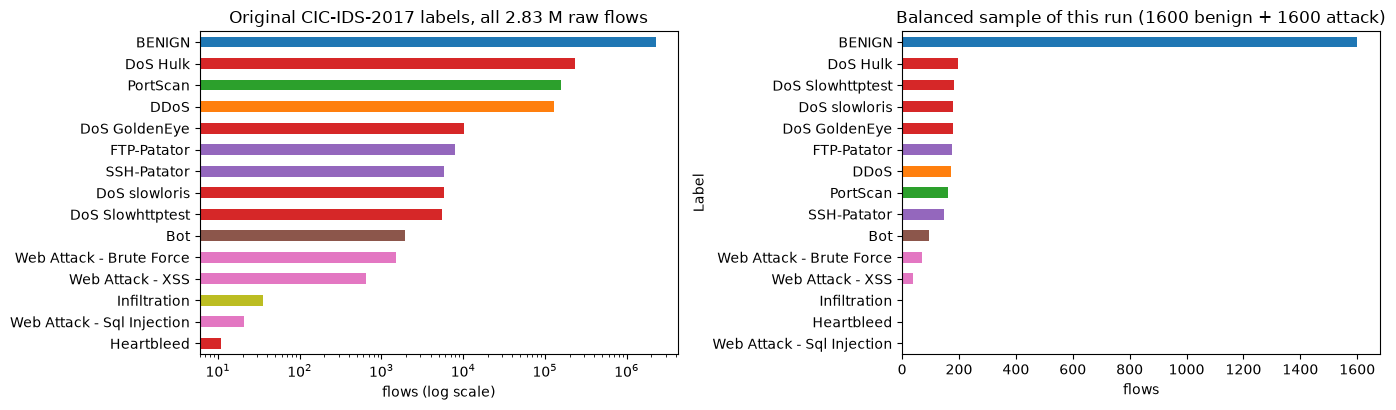

In [6]:
print(f"Raw CIC-IDS-2017: {cic_meta['raw_rows']:,} flows x {cic_meta['raw_columns']} columns (78 numeric features + Label)")
print(f"Cached pool (after removing NaN/inf rows, duplicates and capping): {pool.shape[0]:,} flows x {len(FEATURES)} features")
print("\nFeature names (78):")
print(", ".join(FEATURES))

raw_counts = pd.Series(cic_meta["raw_label_counts"]).sort_values(ascending=False)
table = pd.DataFrame({"raw flows (original labels)": raw_counts,
                      "in cached pool": pool["Label"].value_counts().reindex(raw_counts.index).fillna(0).astype(int)})
table["family"] = [CIC_FAMILY.get(l, "Other") for l in table.index]
print("\nOriginal label values and class counts:")
display(table)

sample_all = pd.concat([SPLIT[k] for k in SPLIT], ignore_index=True)
print("\nBalanced sample used in this run:", sample_all.shape, "| benign:", int((sample_all.Label == "BENIGN").sum()),
      "| attack:", int((sample_all.Label != "BENIGN").sum()))
display(sample_all["Label"].value_counts().to_frame("flows in the balanced sample"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
colors = {"Benign": "tab:blue", "DoS": "tab:red", "DDoS": "tab:orange", "PortScan": "tab:green", "BruteForce": "tab:purple",
          "Botnet": "tab:brown", "WebAttack": "tab:pink", "Infiltration": "tab:olive", "Other": "tab:gray"}
raw_counts.plot.barh(ax=axes[0], color=[colors.get(CIC_FAMILY.get(l, "Other"), "gray") for l in raw_counts.index], logx=True)
axes[0].invert_yaxis(); axes[0].set_xlabel("flows (log scale)"); axes[0].set_title("Original CIC-IDS-2017 labels, all 2.83 M raw flows")
cnt = sample_all["Label"].value_counts()
cnt.plot.barh(ax=axes[1], color=[colors.get(CIC_FAMILY.get(l, "Other"), "gray") for l in cnt.index])
axes[1].invert_yaxis(); axes[1].set_xlabel("flows"); axes[1].set_title(f"Balanced sample of this run ({N_PER_CLASS} benign + {N_PER_CLASS} attack)")
plt.tight_layout(); plt.show()

### Preprocessing for the quantum model (fitted on the training split only)

`make_inputs(split, n)` produces what the circuit really receives: the features are min-max scaled with statistics of the **benign training flows**, test values are clipped to [0, 1], the `2^n` features with the largest benign-training variance are kept (all 78 for `n = 7`, zero-padded to 128), and each vector is scaled to unit length (the paper's `x / ||x||`). The resulting unit vector is the amplitude vector of the `n`-qubit state `|psi(x)> = sum_i x_i |i>`.

In [7]:
def make_inputs(sp, n):
    """Amplitude-embedding inputs for n qubits. Everything is fitted on the benign TRAINING flows only."""
    D = 2 ** n
    X = {k: v[FEATURES].to_numpy(float) for k, v in sp.items()}
    sc = MinMaxScaler().fit(X["ben_tr"])                                    # paper: normalisation; fitted on benign training flows
    T = {k: np.clip(sc.transform(v), 0.0, 1.0) for k, v in X.items()}       # test values clipped to the training range
    var = T["ben_tr"].var(axis=0)
    sel = np.arange(len(FEATURES)) if D >= len(FEATURES) else np.sort(np.argsort(-var)[:D])   # CHOICE: top-variance features if d > 2^n
    def embed(A):
        Z = np.zeros((len(A), D)); Z[:, :len(sel)] = A[:, sel]              # zero padding to 2^n amplitudes (paper)
        nrm = np.linalg.norm(Z, axis=1, keepdims=True); nrm[nrm == 0] = 1.0
        return Z / nrm                                                      # unit length (paper)
    E = {k: embed(v) for k, v in T.items()}
    return dict(E=E, sel=sel, scaler=sc, n=n, D=D, y={k: np.full(len(v), int(k.startswith("att"))) for k, v in sp.items()},
                labels={k: v["Label"].to_numpy() for k, v in sp.items()})

IN7 = make_inputs(SPLIT, 7)
print("7-qubit inputs (all 78 features, zero-padded to 128 amplitudes):", {k: v.shape for k, v in IN7["E"].items()})
print("row norms:", np.round(np.linalg.norm(IN7["E"]["ben_tr"][:5], axis=1), 6), "| features kept:", len(IN7["sel"]))

7-qubit inputs (all 78 features, zero-padded to 128 amplitudes): {'ben_tr': (960, 128), 'ben_va': (320, 128), 'ben_te': (320, 128), 'att_tr': (960, 128), 'att_va': (320, 128), 'att_te': (320, 128)}
row norms: [1. 1. 1. 1. 1.] | features kept: 78


explained variance, scaled features: [0.319 0.203] | amplitude vectors: [0.267 0.186]


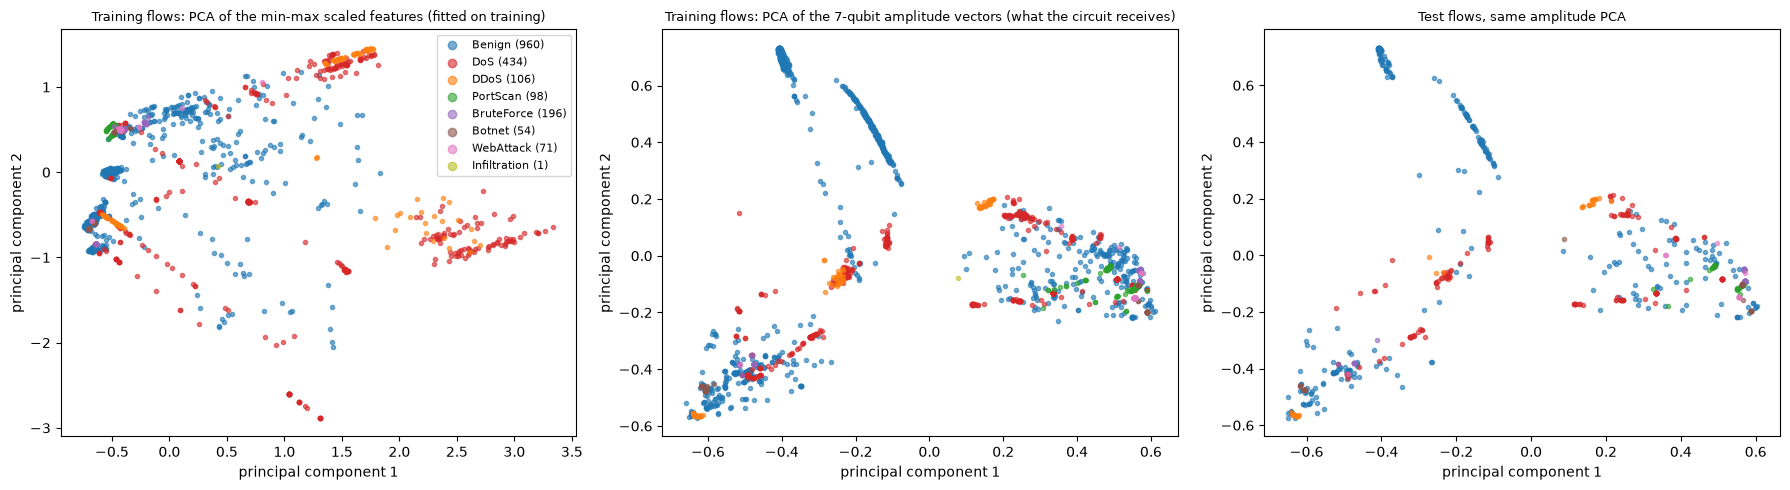

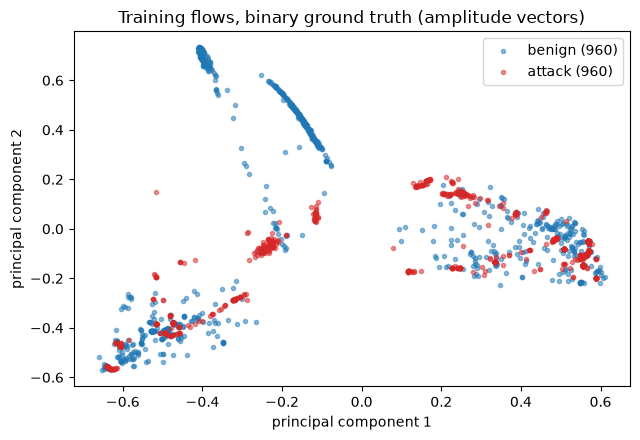

In [8]:
# 2-D scatter of REAL flows coloured by ground truth. PCA is fitted on the training split (benign + attack training flows) only.
def fam(l): return CIC_FAMILY.get(l, "Other")
Xtr_raw = np.vstack([IN7["scaler"].transform(SPLIT["ben_tr"][FEATURES].to_numpy(float)), IN7["scaler"].transform(SPLIT["att_tr"][FEATURES].to_numpy(float))])
Xtr_raw = np.clip(Xtr_raw, 0, 1)
lab_tr = np.r_[SPLIT["ben_tr"]["Label"].to_numpy(), SPLIT["att_tr"]["Label"].to_numpy()]
fam_tr = np.array([fam(l) for l in lab_tr])
Etr7 = np.vstack([IN7["E"]["ben_tr"], IN7["E"]["att_tr"]])
Ete7 = np.vstack([IN7["E"]["ben_te"], IN7["E"]["att_te"]])
lab_te = np.r_[SPLIT["ben_te"]["Label"].to_numpy(), SPLIT["att_te"]["Label"].to_numpy()]
fam_te = np.array([fam(l) for l in lab_te])

pca_raw = PCA(n_components=2, random_state=SEED).fit(Xtr_raw)               # (a) min-max scaled flows
pca_amp = PCA(n_components=2, random_state=SEED).fit(Etr7)                  # (b) the unit amplitude vectors the circuit receives
print("explained variance, scaled features:", np.round(pca_raw.explained_variance_ratio_, 3), "| amplitude vectors:", np.round(pca_amp.explained_variance_ratio_, 3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, Z, f) in zip(axes, [("Training flows: PCA of the min-max scaled features (fitted on training)", pca_raw.transform(Xtr_raw), fam_tr),
                                    ("Training flows: PCA of the 7-qubit amplitude vectors (what the circuit receives)", pca_amp.transform(Etr7), fam_tr),
                                    ("Test flows, same amplitude PCA", pca_amp.transform(Ete7), fam_te)]):
    for name in colors:
        m = f == name
        if m.any():
            ax.scatter(Z[m, 0], Z[m, 1], s=9, alpha=0.6, color=colors[name], label=f"{name} ({m.sum()})")
    ax.set_xlabel("principal component 1"); ax.set_ylabel("principal component 2"); ax.set_title(title, fontsize=9)
axes[0].legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.show()

# The model does not use angle encoding (amplitude embedding instead), so no [0, pi] angle scatter applies. The unit vectors above are the model inputs.
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, c in (("benign", "tab:blue"), ("attack", "tab:red")):
    m = (fam_tr == "Benign") if name == "benign" else (fam_tr != "Benign")
    Z = pca_amp.transform(Etr7)[m]
    ax.scatter(Z[:, 0], Z[:, 1], s=9, alpha=0.5, color=c, label=f"{name} ({m.sum()})")
ax.set_xlabel("principal component 1"); ax.set_ylabel("principal component 2"); ax.set_title("Training flows, binary ground truth (amplitude vectors)"); ax.legend()
plt.tight_layout(); plt.show()

## 2. The quantum autoencoder (Section III-B of the paper)

**State preparation.** A unit vector `x` with `2^n` entries is loaded as `|psi(x)> = sum_i x_i |i>` on `n` qubits (amplitude embedding, `qml.StatePrep`).

**Encoder `U_E(theta_E)`.** `L` times: one `RY` and one `RZ` rotation on every qubit (`U_rot`), then a ring of CNOTs `CNOT(i, (i+1) mod n)` (`U_ent`). After the encoder the first `k = n - N_TRASH` qubits form the **latent register** and the last `N_TRASH` qubits are the **trash**. Tracing out the trash gives the latent state `rho_latent`.

**Decoder `U_D(theta_D)`.** It acts on the latent qubits plus `N_TRASH` fresh auxiliary qubits in `|0>` and has the same layer structure with its own parameters, so the executed circuit has `n + N_TRASH` qubits (the trash qubits are never touched again, which is how a pure-state simulator "traces them out").

**Loss.** `L = 1 - mean_i F(|psi(x_i)>, rho_rec(x_i))` with the overlap fidelity `F = <psi| rho_rec |psi>`. Because the trash is discarded, `rho_rec` is a mixed state and the exact fidelity is the sum over the trash basis states.

**Speed trick, same maths.** Simulating the `(n + N_TRASH)`-qubit statevector of every flow is slow (seconds per step in PennyLane's `default.qubit`). The two circuit halves do not depend on the data, so the notebook builds the `2^n x 2^n` unitaries `U_E` and `U_D` once per step with differentiable NumPy operations and applies them to the whole batch by matrix products. The next section proves, for all three qubit counts, that this gives the same fidelity as the PennyLane circuit that is drawn.

In [9]:
from autograd.extend import primitive, defvjp

def build_layout(n, k, L):
    """Gate list of the quantum autoencoder (n qubits, k latent qubits, L layers per side).
    Encoder: acts on wires 0..n-1 (wires 0..k-1 = latent register, wires k..n-1 = 'trash', discarded afterwards).
    Decoder: acts on the latent wires plus n-k fresh |0> auxiliary wires (n..2n-k-1); 'local' index 0..n-1 = position in that register."""
    latent, trash = list(range(k)), list(range(k, n))
    fresh = list(range(n, 2 * n - k))
    out_reg = latent + fresh                                  # decoder output register (same size n as the input register)
    gates, info, p = [], [], 0                                # gate = (side, name, local wire(s), parameter index or None)
    for side in ("enc", "dec"):
        for layer in range(L):
            for q in range(n):                                # U_rot: one RY and one RZ rotation per qubit (CHOICE)
                gates.append((side, "RY", q, p)); info.append((side, q, layer)); p += 1
                gates.append((side, "RZ", q, p)); info.append((side, q, layer)); p += 1
            for i in range(n):                                # U_ent: ring of CNOT(i, (i+1) mod n)  (paper)
                gates.append((side, "CNOT", (i, (i + 1) % n), None))
    return dict(n=n, k=k, L=L, latent=latent, trash=trash, fresh=fresh, out_reg=out_reg, gates=gates, param_info=info,
                n_params=p, n_wires=2 * n - k)

def apply_side(lay, side, w, mask, stop=None, wire_map=None):
    """Queue the gates of one side. A pruned parameter (mask False) removes its rotation from the circuit.
    stop = parameter index after which to stop (used for 'the state after applying parameter j')."""
    wm = (lambda q: q) if wire_map is None else (lambda q: wire_map[q])
    for s, name, wires, p in lay["gates"]:
        if s != side:
            continue
        if name == "CNOT":
            qml.CNOT(wires=[wm(wires[0]), wm(wires[1])])
        elif mask[p]:
            (qml.RY if name == "RY" else qml.RZ)(w[p], wires=wm(wires))
        if stop is not None and p == stop:
            return

In [10]:
@primitive
def permute_rows(U, perm):
    return U[perm]
defvjp(permute_rows, lambda ans, U, perm: lambda g: g[np.argsort(perm)])      # a permutation is undone by its inverse

def _cnot_perm(n, c, t):
    idx = np.arange(2 ** n)
    flip = ((idx >> (n - 1 - c)) & 1).astype(bool)             # wire 0 = most significant bit (PennyLane convention)
    return np.where(flip, idx ^ (1 << (n - 1 - t)), idx)

def unitary(lay, side, w, mask, stop=None):
    """2^n x 2^n unitary of one side of the circuit, built gate by gate with differentiable array operations
    (RY, RZ rotations as 2x2 blocks, CNOT as a row permutation). Cross-checked against qml.matrix and the QNode statevector below."""
    n = lay["n"]; U = pnp.eye(2 ** n, dtype=complex); pending = None
    for s, name, wires, p in lay["gates"]:
        if s != side:
            continue
        if name == "CNOT":
            q = _cnot_perm(n, *wires)
            pending = q if pending is None else pending[q]          # consecutive CNOTs are merged into one permutation
            continue
        if pending is not None:
            U = permute_rows(U, pending); pending = None
        if mask[p]:
            th = w[p]
            if name == "RY":
                c, sn = pnp.cos(th / 2), pnp.sin(th / 2)
                G = pnp.stack([pnp.stack([c, -sn]), pnp.stack([sn, c])]).astype(complex)
            else:
                G = pnp.stack([pnp.stack([pnp.exp(-0.5j * th), 0.0 * th]), pnp.stack([0.0 * th, pnp.exp(0.5j * th)])]).astype(complex)
            U = pnp.einsum("ij,ajr->air", G, U.reshape(2 ** wires, 2, -1)).reshape(2 ** n, 2 ** n)
        if stop is not None and p == stop:
            return U
    if pending is not None:
        U = permute_rows(U, pending)
    return U

def unitary_pl(lay, side, w, mask):
    """Reference: the same unitary from PennyLane's own qml.matrix (slow, used for the equivalence check only)."""
    return qml.matrix(lambda ww: apply_side(lay, side, ww, mask), wire_order=list(range(lay["n"])))(w)

def fidelities_from_unitaries(lay, X, UE, UD):
    """Exact fidelity <psi| rho_rec |psi> between the input |psi(x)> and the reconstruction rho_rec = U_D (Tr_trash(U_E|psi><psi|U_E^+) x |0><0|) U_D^+.
    rho_rec is mixed because the trash qubits are discarded; summing over the trash basis states t gives the exact mixed-state overlap."""
    n, k = lay["n"], lay["k"]
    Xc = X.astype(complex)
    Phi = (Xc @ UE.T).reshape(len(X), 2 ** k, 2 ** (n - k))            # Phi[b, latent, trash]
    UD0 = UD[:, ::2 ** (n - k)]                                         # decoder columns whose fresh qubits are |0>
    left = pnp.conj(Xc) @ UD0                                           # <psi| U_D |latent basis state>
    amp = pnp.einsum("bl,blt->bt", left, Phi)
    return pnp.sum(pnp.abs(amp) ** 2, axis=1)

def fidelity(lay, X, w, mask):
    return fidelities_from_unitaries(lay, X, unitary(lay, "enc", w, mask), unitary(lay, "dec", w, mask))

In [11]:
def make_state_qnode(lay):
    """The circuit exactly as it is executed on a simulator: 2n-k qubits, amplitude embedding, encoder, decoder acting on
    the latent wires + fresh |0> wires; returns the full statevector (the trash wires are simply left untouched = discarded)."""
    dev = qml.device("default.qubit", wires=lay["n_wires"])
    n = lay["n"]
    @qml.qnode(dev, diff_method="backprop")
    def circuit(x, w, mask):
        qml.StatePrep(x, wires=list(range(n)), normalize=False)          # layer 1: amplitude embedding of the unit-length vector
        apply_side(lay, "enc", w, mask)                                  # layer 2: encoder U_E
        apply_side(lay, "dec", w, mask, wire_map=lay["out_reg"])         #          decoder U_D on latent + fresh |0> wires
        return qml.state()
    return circuit

def fidelities_from_state(lay, circuit, X, w, mask):
    """Same fidelity from the full 2n-k qubit statevector of `circuit` (used to cross-check the fast unitary route)."""
    n, k = lay["n"], lay["k"]
    S = np.asarray(circuit(X, w, mask)); B = len(X)
    S = S.reshape((B,) + (2,) * lay["n_wires"])
    S = np.transpose(S, [0] + [1 + q for q in lay["out_reg"]] + [1 + q for q in lay["trash"]]).reshape(B, 2 ** n, 2 ** (n - k))
    amp = np.einsum("bo,bot->bt", np.conj(X.astype(complex)), S)
    return np.sum(np.abs(amp) ** 2, axis=1)

In [12]:
def train_qae(lay, X_train, epochs, batch, lr, seed, mask=None, w0=None, on_epoch=None):
    """Hybrid loop of Algorithm 1: classical Adam on the loss 1 - mean fidelity; exact gradients by back-propagation through the simulator
    (numerically identical to the parameter-shift rule, checked in the notebook)."""
    r = np.random.default_rng(seed)
    P = lay["n_params"]
    mask = np.ones(P, dtype=bool) if mask is None else mask
    w = pnp.array(r.uniform(0, 2 * np.pi, P) if w0 is None else np.array(w0, dtype=float), requires_grad=True)   # Algorithm 1: init in [0, 2 pi]
    opt = qml.AdamOptimizer(stepsize=lr)
    hist = []
    for ep in range(epochs):
        perm = r.permutation(len(X_train)); losses = []
        for s in range(0, len(X_train), batch):
            xb = pnp.array(X_train[perm[s:s + batch]], requires_grad=False)
            w, c = opt.step_and_cost(lambda ww: 1.0 - pnp.mean(fidelity(lay, xb, ww, mask)), w)
            losses.append(float(c))
        rec = dict(epoch=ep + 1, loss=float(np.mean(losses)))
        if on_epoch is not None:
            rec.update(on_epoch(np.array(w)))
        hist.append(rec)
    return np.array(w), hist

## Quantum Circuit Architecture

This section draws the circuit that is actually executed, for each qubit count compared in the paper, and proves that the fast route used for training computes the same numbers.

* **Encoding.** Amplitude embedding of the unit vector (drawn as `StatePrep`).
* **Parametrised gates.** `RY` and `RZ` on every qubit and layer, `L = N_LAYERS` layers in the encoder and `L` in the decoder; every angle is one trainable parameter.
* **Entanglement.** A ring of `n` CNOTs after each rotation layer.
* **Measurement.** The paper reads the reconstruction fidelity, not a measured bit string. The drawn QNode returns the full statevector; the fidelity with the input is computed from it (cell below). On hardware the same number would be estimated with a swap test or by uncomputing the embedding and measuring `|0...0>`.
* **Assumptions where the paper omits details** (also in the table at the top): depth `L`, the two rotation axes, the number of trash qubits, the wire on which the decoder is attached (latent wires plus fresh wires), the initial angles (uniform in [0, 2 pi] as in Algorithm 1).

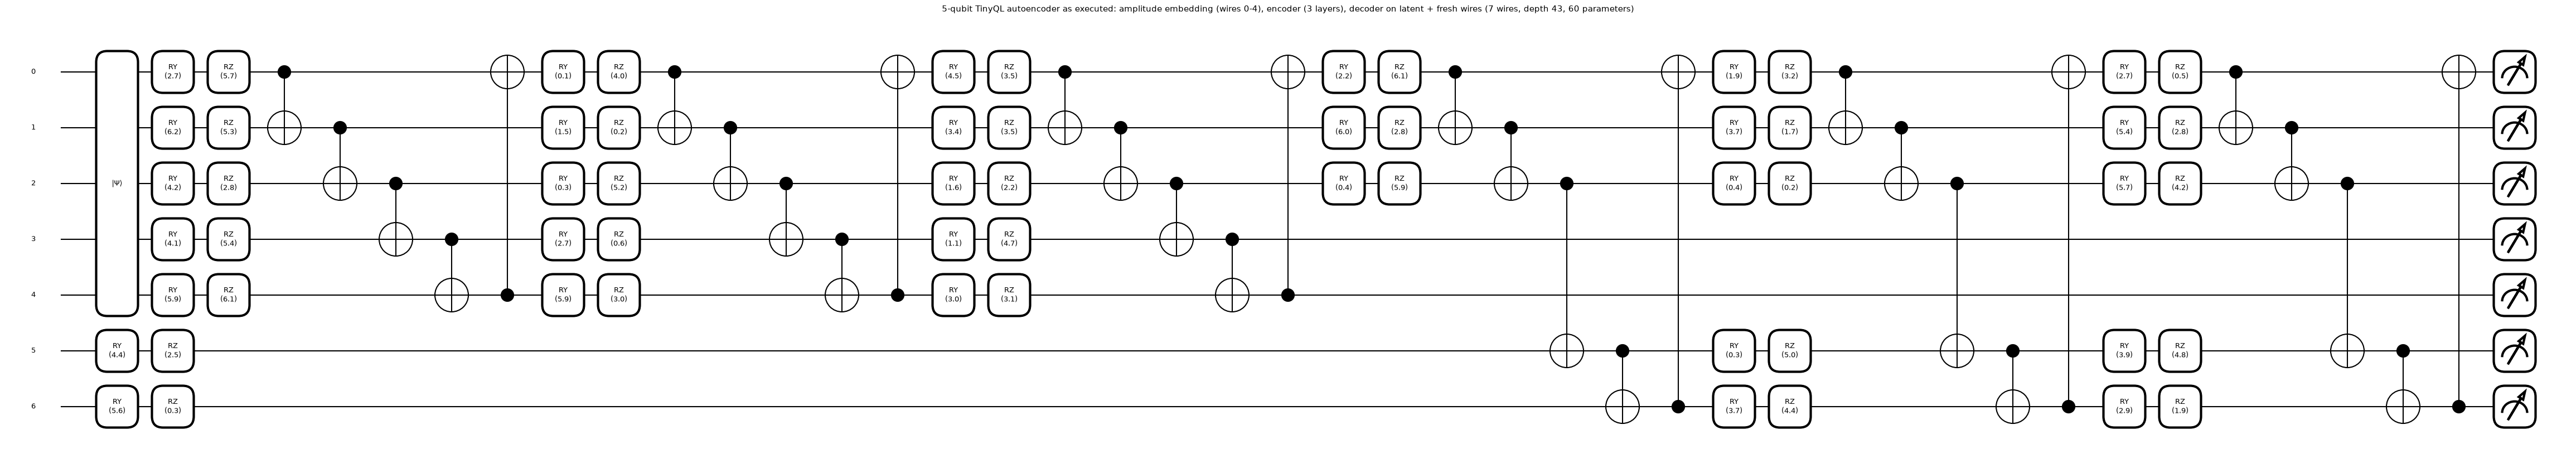

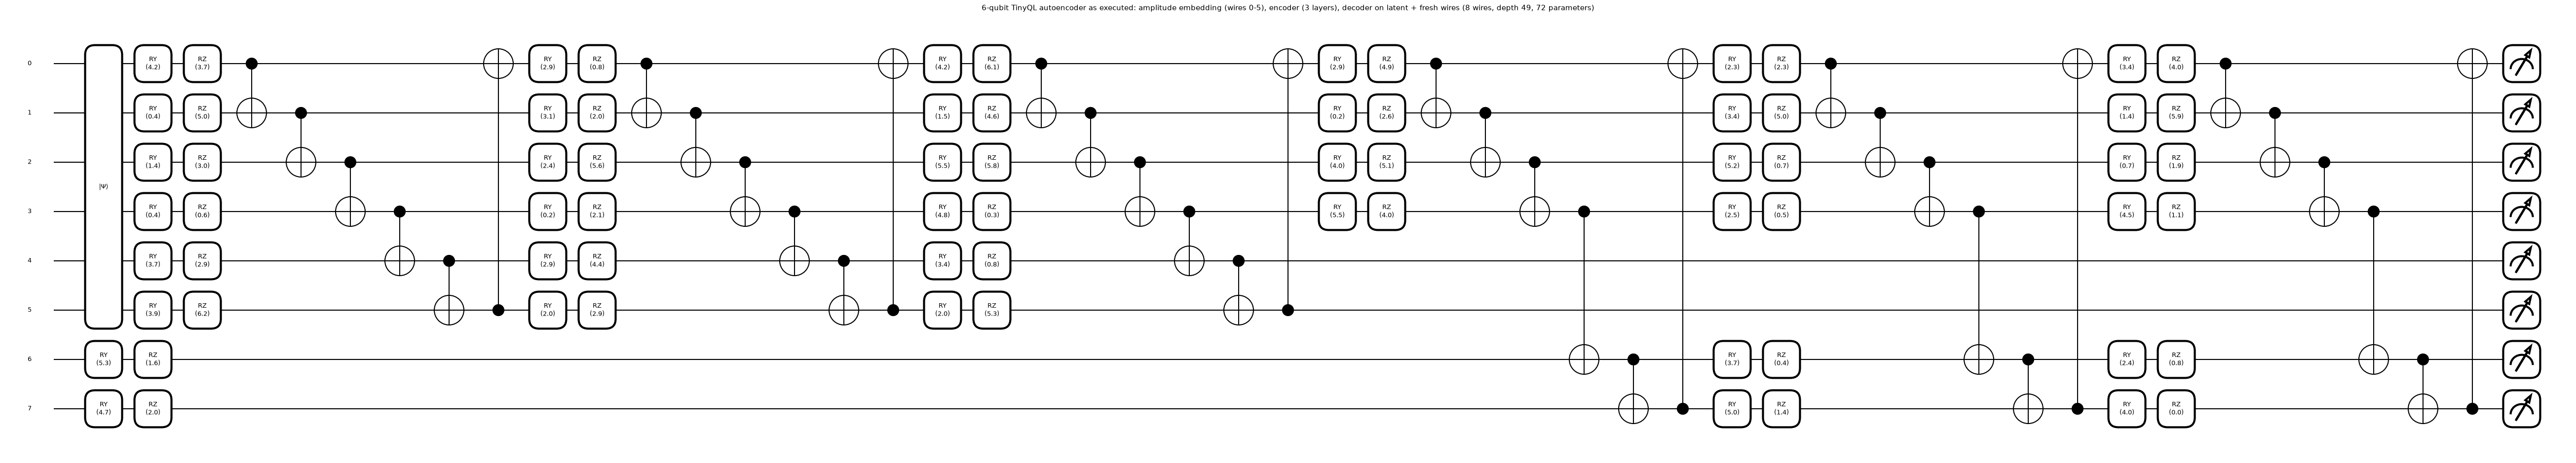

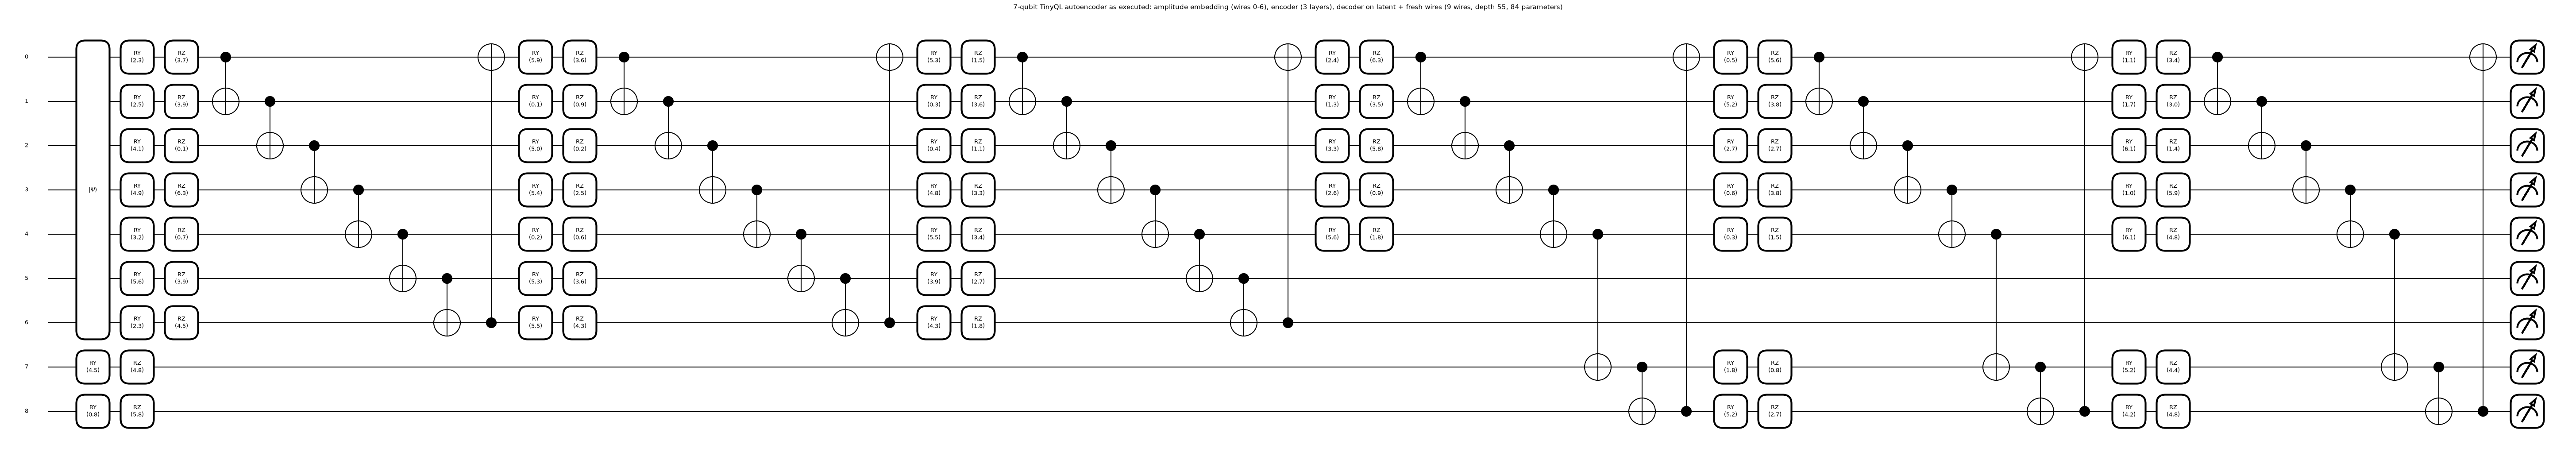

,latent_qubits,trash_qubits,executed_circuit_qubits,depth,gates,trainable_parameters,encoder_params,decoder_params,amplitudes_per_state
n_data_qubits,,,,,,,,,
5,3,2,7,43,91,60,30,30,32
6,4,2,8,49,109,72,36,36,64
7,5,2,9,55,127,84,42,42,128


In [13]:
LAY, QNODE = {}, {}
for n in QUBITS:
    LAY[n] = build_layout(n, n - N_TRASH, N_LAYERS)
    QNODE[n] = make_state_qnode(LAY[n])

x_demo, w_demo = {}, {}
for n in QUBITS:
    r_ = np.random.default_rng(SEED + n)
    x_demo[n] = IN7["E"]["ben_tr"][0] if n == 7 else (lambda v: v / np.linalg.norm(v))(np.abs(r_.normal(size=2 ** n)))   # drawing only needs a valid state vector
    w_demo[n] = r_.uniform(0, 2 * np.pi, LAY[n]["n_params"])

rows = []
for n in QUBITS:
    lay, mask = LAY[n], np.ones(LAY[n]["n_params"], bool)
    sp = qml.specs(QNODE[n])(x_demo[n], w_demo[n], mask)
    res = sp["resources"]
    rows.append(dict(n_data_qubits=n, latent_qubits=lay["k"], trash_qubits=n - lay["k"], executed_circuit_qubits=lay["n_wires"],
                     depth=res.depth, gates=res.num_gates, trainable_parameters=int(mask.sum()),
                     encoder_params=lay["n_params"] // 2, decoder_params=lay["n_params"] // 2, amplitudes_per_state=2 ** n))
    fig, ax = qml.draw_mpl(QNODE[n], decimals=1, fontsize=9)(x_demo[n], w_demo[n], mask)
    ax.set_title(f"{n}-qubit TinyQL autoencoder as executed: amplitude embedding (wires 0-{n-1}), encoder ({N_LAYERS} layers), decoder on latent + fresh wires "
                 f"({lay['n_wires']} wires, depth {res.depth}, {int(mask.sum())} parameters)", fontsize=11)
    plt.show()
arch = pd.DataFrame(rows).set_index("n_data_qubits")
display(arch)

In [14]:
# ---- equivalence of the three routes (drawn QNode == fast unitary route == qml.matrix) and parameter-shift check ----
for n in QUBITS:
    lay = LAY[n]; r_ = np.random.default_rng(SEED + 100 + n)
    w_t = r_.uniform(0, 2 * np.pi, lay["n_params"]); m_t = np.ones(lay["n_params"], bool); m_t[r_.choice(lay["n_params"], 6, replace=False)] = False   # includes pruned gates
    X_t = IN7["E"]["ben_tr"][:12] if n == 7 else (lambda A: A / np.linalg.norm(A, axis=1, keepdims=True))(np.abs(r_.normal(size=(12, 2 ** n))))
    f_fast = np.asarray(fidelity(lay, pnp.array(X_t, requires_grad=False), pnp.array(w_t), m_t)).real
    f_qnode = fidelities_from_state(lay, QNODE[n], X_t, w_t, m_t)
    d_enc = np.abs(np.asarray(unitary(lay, "enc", pnp.array(w_t), m_t)) - np.asarray(unitary_pl(lay, "enc", pnp.array(w_t), m_t))).max()
    d_dec = np.abs(np.asarray(unitary(lay, "dec", pnp.array(w_t), m_t)) - np.asarray(unitary_pl(lay, "dec", pnp.array(w_t), m_t))).max()
    assert np.allclose(f_fast, f_qnode, atol=1e-10) and d_enc < 1e-10 and d_dec < 1e-10
    # parameter-shift rule vs automatic differentiation of the loss, for one kept parameter
    xb = pnp.array(X_t, requires_grad=False)
    loss = lambda ww: 1.0 - pnp.mean(fidelity(lay, xb, ww, m_t))
    g = qml.grad(loss)(pnp.array(w_t, requires_grad=True))
    j = int(np.flatnonzero(m_t)[3]); wp, wm = w_t.copy(), w_t.copy(); wp[j] += np.pi / 2; wm[j] -= np.pi / 2
    shift = 0.5 * (loss(pnp.array(wp)) - loss(pnp.array(wm)))
    assert abs(float(g[j]) - float(shift)) < 1e-9
    print(f"{n} qubits: drawn QNode vs fast route max |dF| = {np.abs(f_fast - f_qnode).max():.1e}; unitaries vs qml.matrix {max(d_enc, d_dec):.1e}; "
          f"d loss/d theta_{j}: autodiff {float(g[j]):+.6f} = parameter-shift {float(shift):+.6f}")
print("All equivalence assertions passed.")

5 qubits: drawn QNode vs fast route max |dF| = 2.8e-17; unitaries vs qml.matrix 2.5e-16; d loss/d theta_3: autodiff -0.001776 = parameter-shift -0.001776


6 qubits: drawn QNode vs fast route max |dF| = 3.5e-17; unitaries vs qml.matrix 2.3e-16; d loss/d theta_3: autodiff +0.000568 = parameter-shift +0.000568


7 qubits: drawn QNode vs fast route max |dF| = 8.7e-18; unitaries vs qml.matrix 2.6e-16; d loss/d theta_3: autodiff -0.003579 = parameter-shift -0.003579
All equivalence assertions passed.


## 3. Detection rule, metrics and the classical models on the same inputs

**Anomaly score.** `1 - F(x)`, the reconstruction infidelity of a flow. A flow is called an attack when its score exceeds a threshold. The paper states the rule `||x - f(x)|| > tau` but not how `tau` is chosen; here it is the value that maximises accuracy on the labelled **validation** split (the test split never influences it). During training, the per-epoch curves use a threshold fitted on a fixed subset of the training split instead, so the validation curve is a genuine generalisation curve.

**Classical models on the same inputs** (all fitted on training data only, same amplitude vectors as the circuit):
* *MLP autoencoder* (scikit-learn) `2^n -> 2^(n-1) -> 2^k -> 2^(n-1) -> 2^n`, trained on benign training flows, score = squared reconstruction error: the "traditional autoencoder" of the paper's comparison.
* *PCA* with `2^k` components (a linear autoencoder), score = squared reconstruction error.
* *Random forest* (200 trees) and *RBF-SVM*: supervised classifiers that see the labelled training flows (benign and attack); they are the usual upper reference for this data and not anomaly detectors.

In [15]:
def stack_part(inp, part):
    """Labelled flows of one split part ('tr', 'va', 'te'): benign first, then attack."""
    Eb, Ea = inp["E"][f"ben_{part}"], inp["E"][f"att_{part}"]
    return np.vstack([Eb, Ea]), np.r_[np.zeros(len(Eb)), np.ones(len(Ea))].astype(int)

def anomaly_scores(lay, w, mask, *Es):
    """Anomaly score 1 - fidelity for one or several input sets; the two circuit unitaries are built once."""
    w = pnp.array(np.asarray(w, float))
    UE, UD = unitary(lay, "enc", w, mask), unitary(lay, "dec", w, mask)
    out = [1.0 - np.asarray(fidelities_from_unitaries(lay, E, UE, UD)).real for E in Es]
    return out[0] if len(Es) == 1 else out

def best_threshold(s, y):
    cands = np.unique(np.quantile(s, np.linspace(0.005, 0.995, 399)))
    return float(cands[int(np.argmax([accuracy_score(y, s > c) for c in cands]))])

def metrics_at(s, y, thr):
    p = (s > thr).astype(int)
    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p, zero_division=0), recall=recall_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0), roc_auc=roc_auc_score(y, s))

def peak_mem_mb(fn):
    """Peak Python/NumPy memory (MB) allocated while running fn(), measured with tracemalloc."""
    tracemalloc.start(); tracemalloc.reset_peak()
    out = fn()
    peak = tracemalloc.get_traced_memory()[1] / 1e6
    tracemalloc.stop()
    return peak, out

def classical_models(inp, n, k, seed):
    """MLP autoencoder, PCA, random forest, RBF-SVM on exactly the amplitude vectors used by the circuit."""
    Etr_b = inp["E"]["ben_tr"]; Etr, ytr = stack_part(inp, "tr"); Eva, yva = stack_part(inp, "va"); Ete, yte = stack_part(inp, "te")
    rows = {}
    h, b = 2 ** (n - 1), 2 ** k
    ae = MLPRegressor(hidden_layer_sizes=(h, b, h), activation="relu", max_iter=AE_EPOCHS, batch_size=AE_BATCH, learning_rate_init=1e-3, random_state=seed)
    t0 = time.perf_counter(); ae.fit(Etr_b, Etr_b); t_fit = time.perf_counter() - t0
    err = lambda E: ((ae.predict(E) - E) ** 2).sum(1)
    thr = best_threshold(err(Eva), yva)
    n_par = sum(c.size for c in ae.coefs_) + sum(i.size for i in ae.intercepts_)
    ae1 = MLPRegressor(hidden_layer_sizes=(h, b, h), max_iter=1, batch_size=AE_BATCH, random_state=seed)
    mem_tr, _ = peak_mem_mb(lambda: ae1.fit(Etr_b, Etr_b))
    mem_inf, _ = peak_mem_mb(lambda: ae.predict(Ete))
    rows["Classical MLP autoencoder"] = dict(**metrics_at(err(Ete), yte, thr), params=n_par, size_bytes=n_par * 8, train_s=t_fit, mem_train_mb=mem_tr, mem_infer_mb=mem_inf)
    pca = PCA(n_components=b, random_state=seed).fit(Etr_b)
    perr = lambda E: ((E - pca.inverse_transform(pca.transform(E))) ** 2).sum(1)
    thr = best_threshold(perr(Eva), yva)
    n_par = pca.components_.size + pca.mean_.size
    rows["PCA (linear autoencoder)"] = dict(**metrics_at(perr(Ete), yte, thr), params=n_par, size_bytes=n_par * 8, train_s=np.nan, mem_train_mb=np.nan, mem_infer_mb=np.nan)
    t0 = time.perf_counter(); rf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1).fit(Etr, ytr); t_fit = time.perf_counter() - t0
    rows["Random forest (supervised)"] = dict(**metrics_at(rf.predict_proba(Ete)[:, 1], yte, 0.5), params=np.nan, size_bytes=np.nan, train_s=t_fit, mem_train_mb=np.nan, mem_infer_mb=np.nan)
    t0 = time.perf_counter(); svm = SVC(kernel="rbf", random_state=seed).fit(Etr, ytr); t_fit = time.perf_counter() - t0
    rows["RBF-SVM (supervised)"] = dict(**metrics_at(svm.decision_function(Ete), yte, 0.0), params=np.nan, size_bytes=np.nan, train_s=t_fit, mem_train_mb=np.nan, mem_infer_mb=np.nan)
    return rows

## 4. Training the original quantum autoencoder (Algorithm 1, Phase 1)

For each qubit count the autoencoder is trained on the **benign training flows only**, starting from angles drawn uniformly in [0, 2 pi]. After every epoch the notebook records the training loss, the mean fidelity, and the detection accuracy on a fixed training subset (threshold fitted there) and on the full validation split (same threshold). The wall-clock training time is recorded for the paper's Table I; peak memory is measured on a separate one-epoch run. `run_original` returns everything later sections need.

In [16]:
def run_original(seed, n, inp):
    lay = LAY[n]; mask = np.ones(lay["n_params"], bool)
    Eb = inp["E"]["ben_tr"]; Etr, ytr = stack_part(inp, "tr"); Eva, yva = stack_part(inp, "va"); Ete, yte = stack_part(inp, "te")
    sub = np.random.default_rng(seed).choice(len(Etr), size=min(600, len(Etr)), replace=False)       # fixed training subset for the curves
    def on_epoch(w):
        s_sub, s_va, s_b = anomaly_scores(lay, w, mask, Etr[sub], Eva, Eb[:200]); thr = best_threshold(s_sub, ytr[sub])
        return dict(train_acc=accuracy_score(ytr[sub], s_sub > thr), val_acc=accuracy_score(yva, s_va > thr), fid_benign=float(1.0 - s_b.mean()))
    t0 = time.perf_counter()
    w, hist = train_qae(lay, Eb, EPOCHS, BATCH, LR, seed * 1000 + n, on_epoch=on_epoch)
    t_train = time.perf_counter() - t0
    s_va, s_te = anomaly_scores(lay, w, mask, Eva, Ete)
    thr = best_threshold(s_va, yva)
    w_init = np.random.default_rng(seed * 1000 + n).uniform(0, 2 * np.pi, lay["n_params"])     # the very same starting angles, no training
    s_va0, s_te0 = anomaly_scores(lay, w_init, mask, Eva, Ete)
    untrained = dict(metrics_at(s_te0, yte, best_threshold(s_va0, yva)), fid_benign=float(1.0 - s_te0[yte == 0].mean()))
    t0 = time.perf_counter(); anomaly_scores(lay, w, mask, Ete); t_inf = time.perf_counter() - t0
    mem_tr, _ = peak_mem_mb(lambda: train_qae(lay, Eb, 1, BATCH, LR, seed))
    mem_inf, _ = peak_mem_mb(lambda: anomaly_scores(lay, w, mask, Ete))
    fid_te = 1.0 - s_te
    return dict(lay=lay, w=w, mask=mask, hist=hist, untrained=untrained, thr=thr, train_s=t_train, infer_s=t_inf, mem_train_mb=mem_tr, mem_infer_mb=mem_inf,
                val_acc=accuracy_score(yva, s_va > thr), s_te=s_te, y_te=yte, fid_benign=float(fid_te[yte == 0].mean()), fid_attack=float(fid_te[yte == 1].mean()),
                **metrics_at(s_te, yte, thr))

## 5. TinyQL compression (Algorithm 1, Phases 2-4)

**Entropy of a parameter.** For parameter `j` (a rotation on qubit `q`), the state right after that gate is formed for benign training flows; the reduced density matrix `rho_j` of qubit `q` is obtained by tracing out all other qubits and `S_j = -Tr(rho_j log2 rho_j)` (between 0 and 1 bit) is averaged over the flows. For decoder parameters the state is the mixture over the discarded trash basis states, because the decoder receives the latent state, not a pure state. Parameters with `S_j < tau_S` are deleted from the circuit (their rotation disappears), the others are fine-tuned for `0.1 * E_max` epochs.

**Quantisation.** For each layer (encoder layer 1..L, decoder layer 1..L) the kept angles, wrapped to [0, 2 pi), are mapped onto a uniform grid of `2^B` levels between their minimum and maximum: `S = (max - min) / (2^B - 1)`, `q = round((theta - min) / S) * S + min` (paper Eq. 1-2). Only the `B`-bit integer codes plus one scale and one zero-point per layer would be stored on a device.

**Guard.** If the validation accuracy of the compressed model falls more than 0.05 below the baseline model's, `tau_S <- 0.9 * tau_S` and the model is pruned again from the baseline weights. The loop stops after `MAX_PRUNE_ITERS` rounds and keeps the last model, flagging it as not converged.

In [17]:
def qubit_rho(S, q, n):
    """Reduced 2x2 density matrix of qubit q for a batch of n-qubit pure states S (rows)."""
    T = S.reshape(len(S), 2 ** q, 2, -1)
    return np.einsum("maxc,mayc->mxy", T, T.conj())

def von_neumann_bits(rho):
    ev = np.clip(np.linalg.eigvalsh(rho), 0.0, None)
    ev = ev / ev.sum(-1, keepdims=True)
    return -np.where(ev > 1e-12, ev * np.log2(np.where(ev > 1e-12, ev, 1.0)), 0.0).sum(-1)

def param_entropies(lay, w, mask, E):
    """S_j for every kept parameter j (NaN for pruned ones): entropy of the reduced state of the gate's qubit right after the gate."""
    n, k = lay["n"], lay["k"]; w = np.asarray(w, float); Ec = E.astype(complex)
    Phi = (Ec @ np.asarray(unitary(lay, "enc", w, mask)).T).reshape(len(E), 2 ** k, 2 ** (n - k))
    dec_inputs = []
    for t in range(2 ** (n - k)):                                    # latent state (x) fresh |0>, one branch per discarded trash basis state
        P = np.zeros((len(E), 2 ** n), complex); P[:, :: 2 ** (n - k)] = Phi[:, :, t]; dec_inputs.append(P)
    out = np.full(len(w), np.nan)
    for j in np.flatnonzero(mask):
        side, q, layer = lay["param_info"][j]
        U = np.asarray(unitary(lay, side, w, mask, stop=j))
        rho = qubit_rho(Ec @ U.T, q, n) if side == "enc" else sum(qubit_rho(P @ U.T, q, n) for P in dec_inputs)
        out[j] = von_neumann_bits(rho).mean()
    return out

def quantize(w, mask, lay, bits):
    """Paper Eq. 1-2 applied per layer of kept angles (wrapped to [0, 2 pi))."""
    wq = np.zeros(len(w)); th = np.mod(np.asarray(w, float), 2 * np.pi)
    groups = {}
    for j in np.flatnonzero(mask):
        side, q, layer = lay["param_info"][j]; groups.setdefault((side, layer), []).append(j)
    for g, idx in groups.items():
        lo, hi = th[idx].min(), th[idx].max(); step = (hi - lo) / (2 ** bits - 1)
        wq[idx] = th[idx] if step == 0 else np.round((th[idx] - lo) / step) * step + lo
    return wq, len(groups)

def model_bytes(n_kept, bits, n_groups):
    payload = math.ceil(n_kept * bits / 8)                            # the B-bit integer codes
    return payload, payload + n_groups * 8                            # + one float32 scale and one float32 zero-point per layer

def run_tinyql(seed, n, inp, base, bits):
    """Phases 2-4 of Algorithm 1 for one bit width, starting from the trained baseline `base`."""
    lay = base["lay"]; Eb = inp["E"]["ben_tr"]; Eva, yva = stack_part(inp, "va"); Ete, yte = stack_part(inp, "te"); Etr, ytr = stack_part(inp, "tr")
    S_j = param_entropies(lay, base["w"], base["mask"], Eb[:ENT_SAMPLE])
    tau = float(np.nanquantile(S_j, PRUNE_QUANTILE)); acc_base = base["val_acc"]; log = []
    for it in range(MAX_PRUNE_ITERS):
        mask = base["mask"] & ~(S_j < tau)                                              # Phase 2: remove parameters with S_j < tau_S
        w0 = np.where(mask, base["w"], 0.0)
        w_ft, hist = train_qae(lay, Eb, FT_EPOCHS, BATCH, LR_FT, seed * 1000 + n + 7 * it, mask=mask, w0=w0)   # FINE TUNE (0.1 E_max)
        wq, n_groups = quantize(w_ft, mask, lay, bits)                                  # Phase 3: B-bit quantisation
        s_va = anomaly_scores(lay, wq, mask, Eva); acc = accuracy_score(yva, s_va > best_threshold(s_va, yva))   # Phase 4: validation
        log.append(dict(iteration=it + 1, tau_S=tau, kept=int(mask.sum()), val_acc=acc, drop=acc_base - acc))
        if acc_base - acc <= ACC_DROP_TOL:
            break
        tau *= TAU_SHRINK                                                               # tau_S <- 0.9 tau_S, goto Phase 2
    converged = (acc_base - acc) <= ACC_DROP_TOL
    thr = best_threshold(s_va, yva)
    s_te, s_tr = anomaly_scores(lay, wq, mask, Ete, Etr)
    payload, total = model_bytes(int(mask.sum()), bits, n_groups)
    return dict(mask=mask, w=wq, tau=tau, entropies=S_j, log=log, converged=converged, thr=thr, ft_hist=hist, kept=int(mask.sum()),
                prune_frac=1 - mask.sum() / lay["n_params"], payload_bytes=payload, size_bytes=total, bits=bits, s_te=s_te, y_te=yte,
                train_acc=accuracy_score(ytr, s_tr > thr), val_acc=acc, fid_benign=float(1.0 - s_te[yte == 0].mean()),
                orig_bytes=lay["n_params"] * 8, mem_saving=1 - payload / (lay["n_params"] * 8), **metrics_at(s_te, yte, thr))

## 6. Run everything

For every seed and every qubit count: build the amplitude-embedding inputs, train the original quantum autoencoder, apply TinyQL with 4-bit and 8-bit quantisation, and fit the classical models. Progress is printed as it goes. Timings are wall-clock on the machine running the notebook (a shared CPU, so use them for ratios, not as absolute values).

In [18]:
RES, INP = {}, {}
t_all = time.time()
for seed in SEEDS:
    sp = SPLIT if seed == SEED else draw_split(seed)
    for n in QUBITS:
        inp = make_inputs(sp, n); INP[(seed, n)] = inp
        t0 = time.time()
        base = run_original(seed, n, inp)
        tiny = {b: run_tinyql(seed, n, inp, base, b) for b in BITS}
        cls = classical_models(inp, n, n - N_TRASH, seed)
        RES[(seed, n)] = dict(base=base, tiny=tiny, cls=cls)
        print(f"seed {seed} | {n} qubits ({LAY[n]['n_params']} parameters): original acc {base['accuracy']:.3f} (fidelity benign {base['fid_benign']:.3f}, attack {base['fid_attack']:.3f}), "
              f"train {base['train_s']:.0f} s | " + " | ".join(f"TinyQL {b}-bit acc {tiny[b]['accuracy']:.3f}, kept {tiny[b]['kept']}/{LAY[n]['n_params']}"
              f"{'' if tiny[b]['converged'] else ' (guard not satisfied)'}" for b in BITS) + f" | {time.time() - t0:.0f} s")
print(f"total {time.time() - t_all:.0f} s")

seed 42 | 5 qubits (60 parameters): original acc 0.733 (fidelity benign 0.452, attack 0.140), train 130 s | TinyQL 4-bit acc 0.728, kept 30/60 | TinyQL 8-bit acc 0.714, kept 30/60 | 151 s


seed 42 | 6 qubits (72 parameters): original acc 0.542 (fidelity benign 0.268, attack 0.320), train 159 s | TinyQL 4-bit acc 0.658, kept 36/72 | TinyQL 8-bit acc 0.619, kept 36/72 | 192 s


seed 42 | 7 qubits (84 parameters): original acc 0.694 (fidelity benign 0.258, attack 0.044), train 230 s | TinyQL 4-bit acc 0.653, kept 74/84 | TinyQL 8-bit acc 0.644, kept 48/84 | 322 s


seed 43 | 5 qubits (60 parameters): original acc 0.734 (fidelity benign 0.518, attack 0.207), train 130 s | TinyQL 4-bit acc 0.703, kept 50/60 | TinyQL 8-bit acc 0.703, kept 50/60 | 169 s


seed 43 | 6 qubits (72 parameters): original acc 0.728 (fidelity benign 0.464, attack 0.137), train 184 s | TinyQL 4-bit acc 0.711, kept 64/72 | TinyQL 8-bit acc 0.744, kept 64/72 | 273 s


seed 43 | 7 qubits (84 parameters): original acc 0.709 (fidelity benign 0.419, attack 0.115), train 242 s | TinyQL 4-bit acc 0.695, kept 42/84 | TinyQL 8-bit acc 0.695, kept 42/84 | 279 s
total 1386 s


## 7. Results: the paper's Table I and Figures 2-9 re-computed

All numbers below are on the **balanced test split** (flows never used for fitting or for any choice). "Accuracy" is the detection accuracy at the validation-chosen threshold; "fidelity" is the mean reconstruction fidelity of benign test flows, which is what the loss optimises and is the other plausible reading of the paper's word "accuracy".

In [19]:
MET = ["accuracy", "precision", "recall", "f1", "roc_auc"]
rows = []
for (seed, n), r in RES.items():
    b = r["base"]; P = LAY[n]["n_params"]
    rows.append(dict(seed=seed, n=n, model="Original quantum AE (64-bit angles)", bits=64, params=P, size_bytes=P * 8, fid_benign=b["fid_benign"], train_s=b["train_s"],
                     mem_train_mb=b["mem_train_mb"], mem_infer_mb=b["mem_infer_mb"], **{m: b[m] for m in MET}))
    rows.append(dict(seed=seed, n=n, model="Untrained circuit (same random angles, no training)", bits=64, params=P, size_bytes=P * 8, fid_benign=b["untrained"]["fid_benign"],
                     train_s=0.0, mem_train_mb=np.nan, mem_infer_mb=np.nan, **{m: b["untrained"][m] for m in MET}))
    for bits, t in r["tiny"].items():
        rows.append(dict(seed=seed, n=n, model=f"TinyQL {bits}-bit", bits=bits, params=t["kept"], size_bytes=t["size_bytes"], fid_benign=t["fid_benign"], train_s=b["train_s"],
                         mem_train_mb=b["mem_train_mb"], mem_infer_mb=b["mem_infer_mb"], **{m: t[m] for m in MET}))
    for name, c in r["cls"].items():
        rows.append(dict(seed=seed, n=n, model=name, bits=64, fid_benign=np.nan, **c))
SUMM = pd.DataFrame(rows)
order = (["Untrained circuit (same random angles, no training)", "Original quantum AE (64-bit angles)"] + [f"TinyQL {b}-bit" for b in BITS]
         + ["Classical MLP autoencoder", "PCA (linear autoencoder)", "Random forest (supervised)", "RBF-SVM (supervised)"])
agg = SUMM.groupby(["n", "model"]).agg(**{f"{m}": (m, "mean") for m in MET}, **{f"{m}_std": (m, "std") for m in ["accuracy", "f1"]},
                                       fidelity=("fid_benign", "mean"), params=("params", "mean"), size_bytes=("size_bytes", "mean"), train_s=("train_s", "mean"))
agg = agg.reindex([(n, m) for n in QUBITS for m in order])
print(f"Test-split results, mean over seeds {SEEDS} (std of accuracy / F1 is NaN with one seed):")
display(agg.round(4))

Test-split results, mean over seeds (42, 43) (std of accuracy / F1 is NaN with one seed):

accuracy  precision  recall      f1  roc_auc  accuracy_std  f1_std  fidelity   params  size_bytes   train_s
n model                                                                                                                                                          
5 Untrained circuit (same random angles, no train...    0.6711     0.6595  0.7078  0.6820   0.6551        0.0144  0.0291    0.0385     60.0       480.0    0.0000
  Original quantum AE (64-bit angles)                   0.7336     0.6834  0.8719  0.7658   0.7320        0.0011  0.0074    0.4852     60.0       480.0  129.7674
  TinyQL 4-bit                                          0.7156     0.6830  0.8500  0.7462   0.7114        0.0177  0.0329    0.2120     40.0        64.0  129.7674
  TinyQL 8-bit                                          0.7086     0.6655  0.8672  0.7459   0.7108        0.0077  0.0333    0.2181     40.0        84.0  129.7674
  Classical MLP autoencoder                             0.7500     0.7245  0.8141  0.7648   0.7988        0.0110  0.0072       NaN   1352.0     10816.0    2.2128
  PCA (linear autoencoder)                              0.7305     0.6682  0.9156  0.7726   0.7200        0.0276  0.0231       NaN    288.0      2304.0       NaN
  Random forest (supervised)                            0.9727     0.9764  0.9688  0.9726   0.9953        0.0033  0.0032       NaN      NaN         NaN    2.4019
  RBF-SVM (supervised)                                  0.9164     0.9185  0.9141  0.9162   0.9665        0.0055  0.0049       NaN      NaN         NaN    0.1970
6 Untrained circuit (same random angles, no train...    0.6336     0.6026  0.8203  0.6931   0.5835        0.0829  0.0444    0.0165     72.0       576.0    0.0000
  Original quantum AE (64-bit angles)                   0.6352     0.6069  0.9000  0.7163   0.5689        0.1315  0.0507    0.3660     72.0       576.0  171.4592
  TinyQL 4-bit                                          0.6844     0.6352  0.8844  0.7374   0.6763        0.0376  0.0086    0.1296     50.0        69.0  171.4592
  TinyQL 8-bit                                          0.6812     0.6453  0.7984  0.7136   0.6851        0.0884  0.0865    0.1429     50.0        94.0  171.4592
  Classical MLP autoencoder                             0.7086     0.6541  0.9156  0.7587   0.7593        0.0387  0.0013       NaN   5264.0     42112.0    1.4573
  PCA (linear autoencoder)                              0.7000     0.6517  0.8609  0.7417   0.7964        0.0177  0.0088       NaN   1088.0      8704.0       NaN
  Random forest (supervised)                            0.9773     0.9811  0.9734  0.9773   0.9957        0.0033  0.0033       NaN      NaN         NaN    2.7804
  RBF-SVM (supervised)                                  0.9156     0.9172  0.9141  0.9155   0.9699        0.0044  0.0031       NaN      NaN         NaN    0.2486
7 Untrained circuit (same random angles, no train...    0.6148     0.6092  0.6594  0.6295   0.5521        0.0122  0.0303    0.0060     84.0       672.0    0.0000
  Original quantum AE (64-bit angles)                   0.7016     0.6263  1.0000  0.7702   0.6127        0.0110  0.0066    0.3381     84.0       672.0  236.3701
  TinyQL 4-bit                                          0.6742     0.6335  0.8281  0.7146   0.6897        0.0298  0.0567    0.1153     58.0        69.0  236.3701
  TinyQL 8-bit                                          0.6695     0.6338  0.8047  0.7041   0.6642        0.0365  0.0716    0.0887     45.0        81.0  236.3701
  Classical MLP autoencoder                             0.7359     0.6876  0.8688  0.7661   0.7827        0.0066  0.0227       NaN  20768.0    166144.0    1.5757
  PCA (linear autoencoder)                              0.7367     0.6996  0.8547  0.7634   0.8188        0.0188  0.0157       NaN   4224.0     33792.0       NaN
  Random forest (supervised)                            0.9758     0.9795  0.9719  0.9757   0.9953        0.0055  0.0056       NaN      NaN         NaN    2.7973
  RB

In [20]:
# Table I of the paper, re-computed (first seed; 8-bit TinyQL)
t1 = []
PAPER_T1 = {5: (0.877, 87.6313), 6: (0.9780, 314.6332), 7: (0.9806, 425.8099)}
for n in QUBITS:
    r = RES[(SEED, n)]; t = r["tiny"][8]
    t1.append({"qubits": n, "paper classical memory (2*2^n bytes)": f"{2 * 2 ** n} B", "TinyQL model size (8-bit payload)": f"{t['payload_bytes']} B (+{t['size_bytes'] - t['payload_bytes']} B scales)",
               "original model size (64-bit)": f"{r['base']['lay']['n_params'] * 8} B", "state vector of one circuit (complex128)": f"{16 * 2 ** (LAY[n]['n_wires'])} B",
               "paper accuracy": PAPER_T1[n][0], "notebook accuracy": round(t["accuracy"], 4), "notebook fidelity (benign)": round(t["fid_benign"], 4),
               "paper training time (s)": PAPER_T1[n][1], "notebook training time (s)": round(r["base"]["train_s"], 1)})
display(pd.DataFrame(t1).set_index("qubits").T)

qubits,5,6,7
paper classical memory (2*2^n bytes),64 B,128 B,256 B
TinyQL model size (8-bit payload),30 B (+40 B scales),36 B (+40 B scales),48 B (+40 B scales)
original model size (64-bit),480 B,576 B,672 B
state vector of one circuit (complex128),2048 B,4096 B,8192 B
paper accuracy,0.877,0.978,0.9806
notebook accuracy,0.7141,0.6188,0.6438
notebook fidelity (benign),0.1024,0.0697,0.054
paper training time (s),87.6313,314.6332,425.8099
notebook training time (s),129.8,158.9,230.3


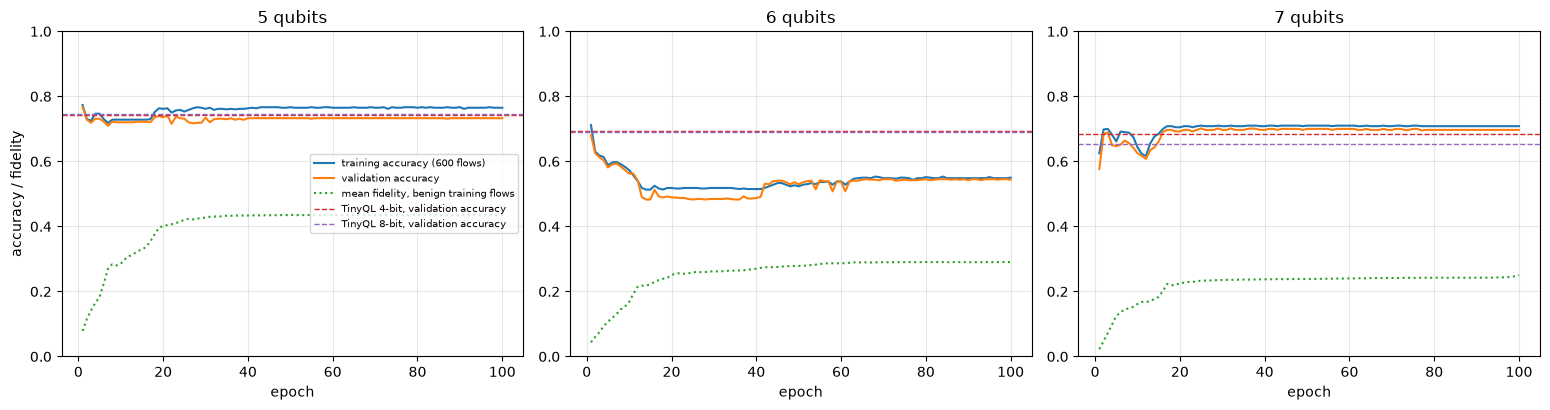

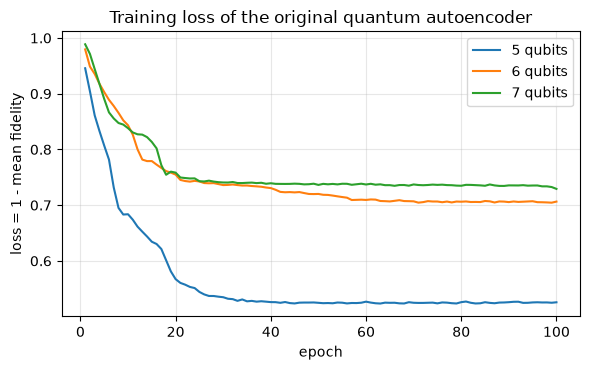

In [21]:
# Figures 2 / 9 of the paper: accuracy during training and validation, per qubit count
fig, axes = plt.subplots(1, len(QUBITS), figsize=(5.2 * len(QUBITS), 4.2), sharey=False)
for ax, n in zip(np.atleast_1d(axes), QUBITS):
    r = RES[(SEED, n)]; h = pd.DataFrame(r["base"]["hist"])
    ax.plot(h.epoch, h.train_acc, label="training accuracy (600 flows)", color="tab:blue")
    ax.plot(h.epoch, h.val_acc, label="validation accuracy", color="tab:orange")
    ax.plot(h.epoch, h.fid_benign, label="mean fidelity, benign training flows", color="tab:green", ls=":")
    for bits, c in zip(BITS, ("tab:red", "tab:purple")):
        ax.axhline(r["tiny"][bits]["val_acc"], color=c, ls="--", lw=1, label=f"TinyQL {bits}-bit, validation accuracy")
    ax.set_xlabel("epoch"); ax.set_title(f"{n} qubits"); ax.set_ylim(0.0, 1.0); ax.grid(alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("accuracy / fidelity"); np.atleast_1d(axes)[0].legend(fontsize=7, loc="center right")
plt.tight_layout(); plt.show()

# training loss
fig, ax = plt.subplots(figsize=(6, 3.8))
for n in QUBITS:
    h = pd.DataFrame(RES[(SEED, n)]["base"]["hist"]); ax.plot(h.epoch, h.loss, label=f"{n} qubits")
ax.set_xlabel("epoch"); ax.set_ylabel("loss = 1 - mean fidelity"); ax.set_title("Training loss of the original quantum autoencoder"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### What the entropy pruning removes

Each dot is one circuit parameter. The vertical axis is its entropy `S_j` (bits) after the baseline training; the dashed line is the final threshold `tau_S` of the 8-bit run; dots below it are deleted. The table lists the iterations of the guard loop of Algorithm 1 for every configuration.

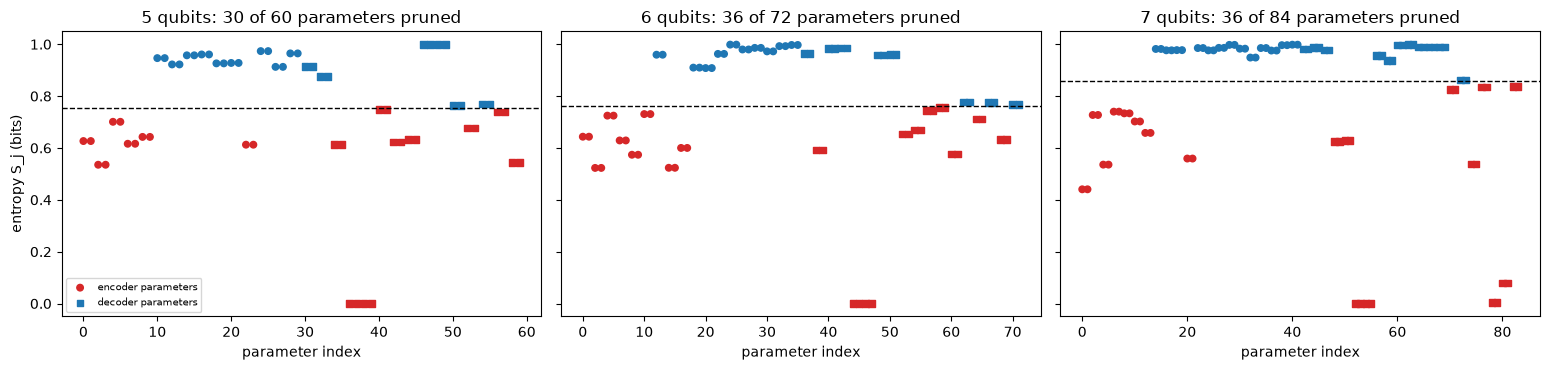

,seed,qubits,bits,iteration,tau_S,kept,val_acc,drop,converged
0,42,5,4,1,0.7560,30,0.7422,-0.0094,True
1,42,5,8,1,0.7560,30,0.7469,-0.0141,True
2,42,6,4,1,0.7618,36,0.6922,-0.1437,True
3,42,6,8,1,0.7618,36,0.6891,-0.1406,True
4,42,7,4,1,0.9526,42,0.6469,0.0531,
5,42,7,4,2,0.8573,48,0.6484,0.0516,
6,42,7,4,3,0.7716,54,0.6094,0.0906,
7,42,7,4,4,0.6944,62,0.6094,0.0906,
8,42,7,4,5,0.6250,68,0.6094,0.0906,
9,42,7,4,6,0.5625,68,0.6094,0.0906,


In [22]:
fig, axes = plt.subplots(1, len(QUBITS), figsize=(5.2 * len(QUBITS), 3.8), sharey=True)
for ax, n in zip(np.atleast_1d(axes), QUBITS):
    t = RES[(SEED, n)]["tiny"][8]; S = t["entropies"]; info = LAY[n]["param_info"]
    side = np.array([i[0] for i in info]); layer = np.array([i[2] for i in info])
    for sd, mk in (("enc", "o"), ("dec", "s")):
        m = side == sd
        ax.scatter(np.flatnonzero(m), S[m], marker=mk, s=22, c=np.where(S[m] < t["tau"], "tab:red", "tab:blue"), label=f"{'encoder' if sd == 'enc' else 'decoder'} parameters")
    ax.axhline(t["tau"], color="k", ls="--", lw=1); ax.set_xlabel("parameter index"); ax.set_title(f"{n} qubits: {int((S < t['tau']).sum())} of {len(S)} parameters pruned")
np.atleast_1d(axes)[0].set_ylabel("entropy S_j (bits)"); np.atleast_1d(axes)[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

log_rows = []
for (seed, n), r in RES.items():
    for bits, t in r["tiny"].items():
        for l in t["log"]:
            log_rows.append(dict(seed=seed, qubits=n, bits=bits, **l, converged=t["converged"] if l["iteration"] == len(t["log"]) else ""))
display(pd.DataFrame(log_rows).round(4))

### The pruned and quantised circuit

TinyQL changes the circuit: pruned rotations disappear. The drawing below is the executed QNode of the middle qubit count with the 8-bit TinyQL angles and the pruned mask. It is a different architecture from the original one drawn above, so it gets its own drawing and its own qubit, depth and parameter count.

TinyQL 6-qubit, 8-bit: executed circuit qubits 8, depth 45 (original 6-qubit circuit: see table above), gates 73, trainable parameters 36 of 72


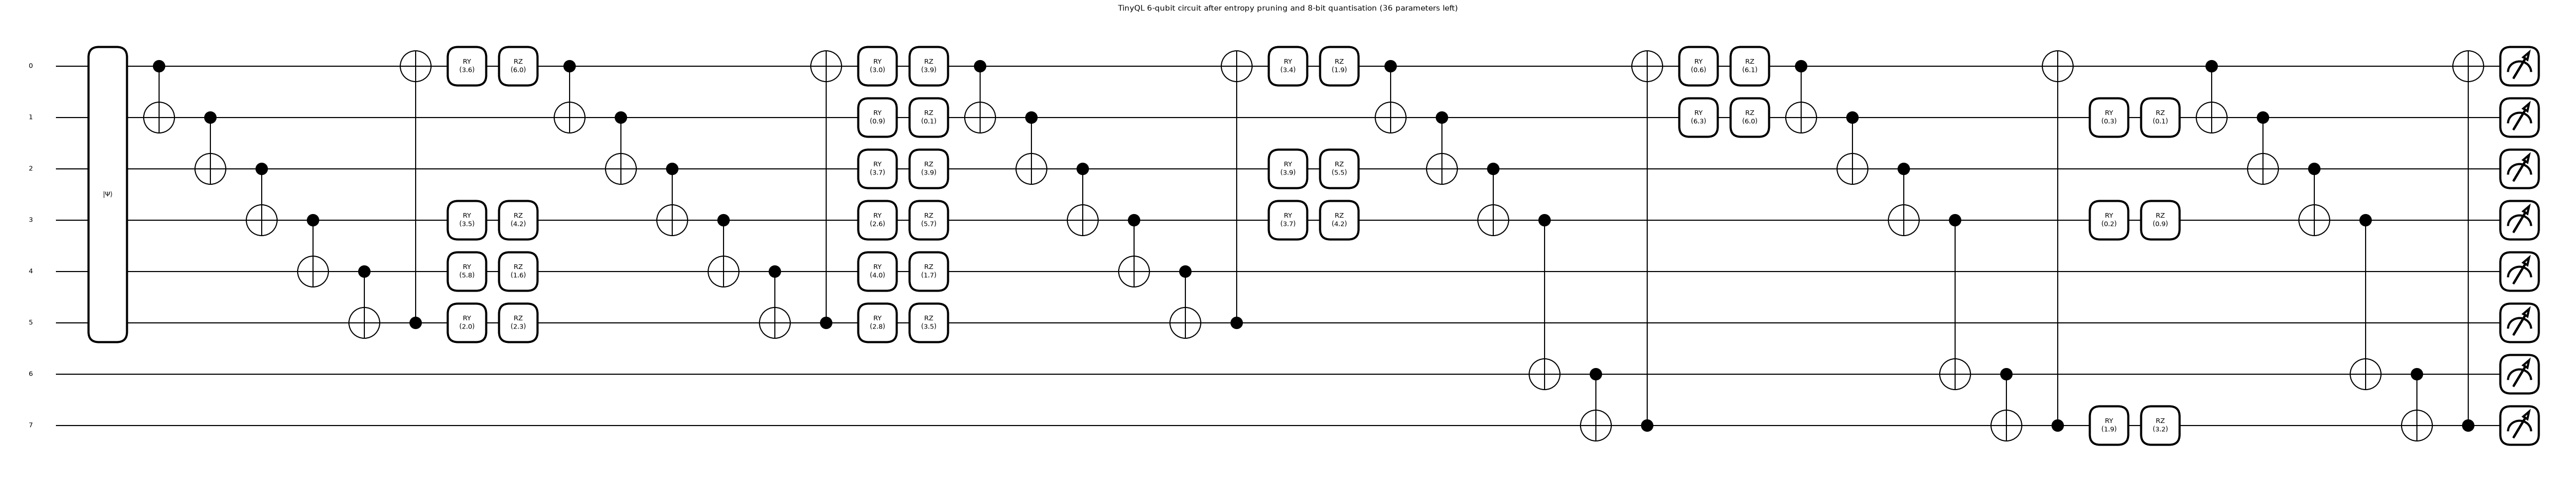

In [23]:
n_mid = QUBITS[len(QUBITS) // 2]; t = RES[(SEED, n_mid)]["tiny"][8]
sp = qml.specs(QNODE[n_mid])(INP[(SEED, n_mid)]["E"]["ben_tr"][0], t["w"], t["mask"])
print(f"TinyQL {n_mid}-qubit, 8-bit: executed circuit qubits {LAY[n_mid]['n_wires']}, depth {sp['resources'].depth} (original {n_mid}-qubit circuit: see table above), "
      f"gates {sp['resources'].num_gates}, trainable parameters {int(t['mask'].sum())} of {LAY[n_mid]['n_params']}")
fig, ax = qml.draw_mpl(QNODE[n_mid], decimals=1, fontsize=9)(INP[(SEED, n_mid)]["E"]["ben_tr"][0], t["w"], t["mask"])
ax.set_title(f"TinyQL {n_mid}-qubit circuit after entropy pruning and 8-bit quantisation ({int(t['mask'].sum())} parameters left)", fontsize=11)
plt.show()

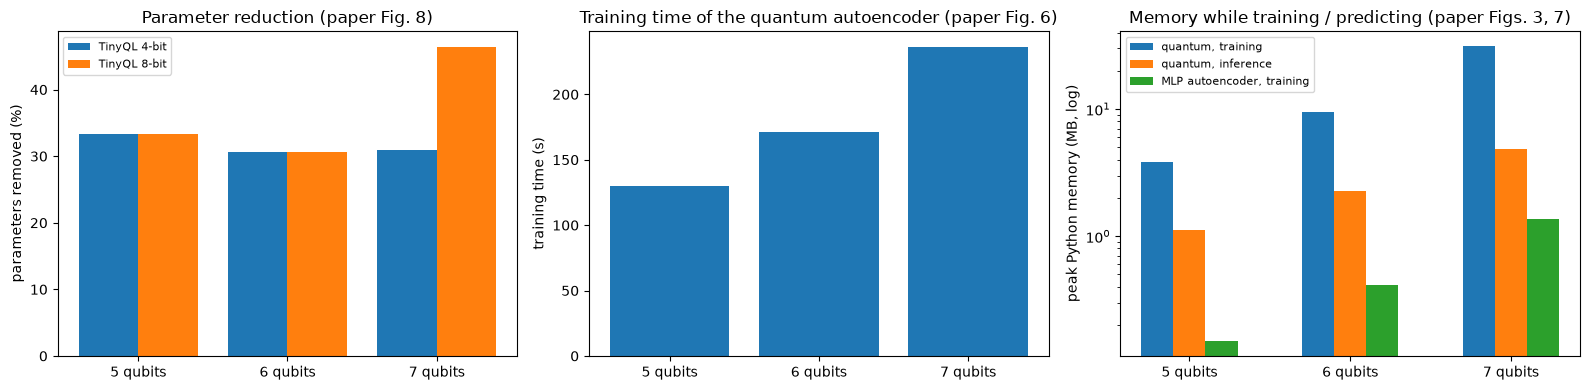

,original_params,original_bytes,TinyQL 4-bit: kept / payload bytes / saving,TinyQL 8-bit: kept / payload bytes / saving,mlp_ae_params
qubits,,,,,
5,60,480,30 / 15 B / 96.88 %,30 / 30 B / 93.75 %,1352
6,72,576,36 / 18 B / 96.88 %,36 / 36 B / 93.75 %,5264
7,84,672,74 / 37 B / 94.49 %,48 / 48 B / 92.86 %,20768


In [24]:
# Figure 8 (parameter reduction), Figure 6 (training time) and Figures 3 / 7 (memory)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
w_ = 0.8 / len(BITS)
for i, bits in enumerate(BITS):
    pf = [100 * np.mean([RES[(s, n)]["tiny"][bits]["prune_frac"] for s in SEEDS]) for n in QUBITS]
    axes[0].bar(np.arange(len(QUBITS)) + i * w_, pf, width=w_, label=f"TinyQL {bits}-bit")
axes[0].set_xticks(np.arange(len(QUBITS)) + 0.4 - w_ / 2); axes[0].set_xticklabels([f"{n} qubits" for n in QUBITS]); axes[0].set_ylabel("parameters removed (%)")
axes[0].set_title("Parameter reduction (paper Fig. 8)"); axes[0].legend(fontsize=8)
axes[1].bar([f"{n} qubits" for n in QUBITS], [np.mean([RES[(s, n)]["base"]["train_s"] for s in SEEDS]) for n in QUBITS], color="tab:blue")
axes[1].set_ylabel("training time (s)"); axes[1].set_title("Training time of the quantum autoencoder (paper Fig. 6)")
mt = [np.mean([RES[(s, n)]["base"]["mem_train_mb"] for s in SEEDS]) for n in QUBITS]; mi = [np.mean([RES[(s, n)]["base"]["mem_infer_mb"] for s in SEEDS]) for n in QUBITS]
ct = [np.mean([RES[(s, n)]["cls"]["Classical MLP autoencoder"]["mem_train_mb"] for s in SEEDS]) for n in QUBITS]
xs = np.arange(len(QUBITS)); axes[2].bar(xs - 0.2, mt, 0.2, label="quantum, training"); axes[2].bar(xs, mi, 0.2, label="quantum, inference")
axes[2].bar(xs + 0.2, ct, 0.2, label="MLP autoencoder, training"); axes[2].set_xticks(xs); axes[2].set_xticklabels([f"{n} qubits" for n in QUBITS])
axes[2].set_yscale("log"); axes[2].set_ylabel("peak Python memory (MB, log)"); axes[2].set_title("Memory while training / predicting (paper Figs. 3, 7)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

size_rows = []
for n in QUBITS:
    r = RES[(SEED, n)]; P = LAY[n]["n_params"]
    size_rows.append(dict(qubits=n, original_params=P, original_bytes=P * 8, **{f"TinyQL {b}-bit: kept / payload bytes / saving": f"{r['tiny'][b]['kept']} / {r['tiny'][b]['payload_bytes']} B / {100 * r['tiny'][b]['mem_saving']:.2f} %" for b in BITS},
                          mlp_ae_params=int(r["cls"]["Classical MLP autoencoder"]["params"])))
display(pd.DataFrame(size_rows).set_index("qubits"))

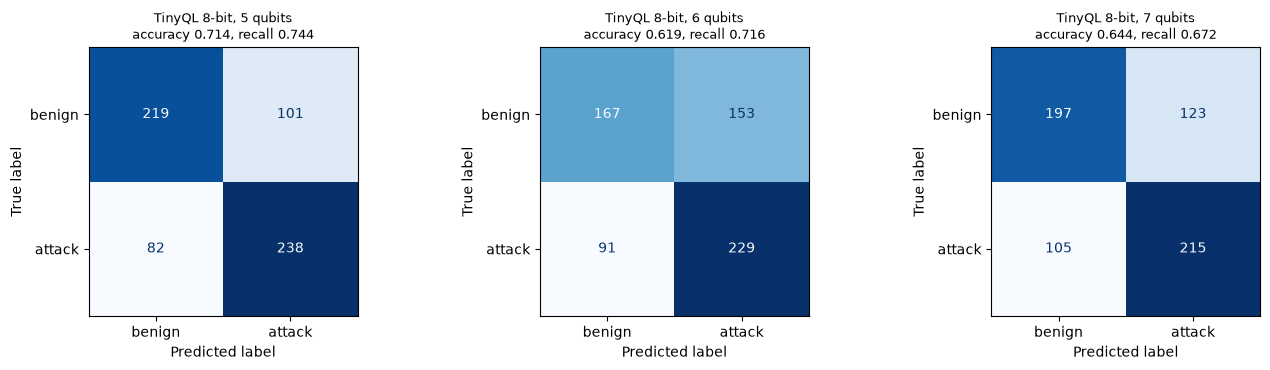

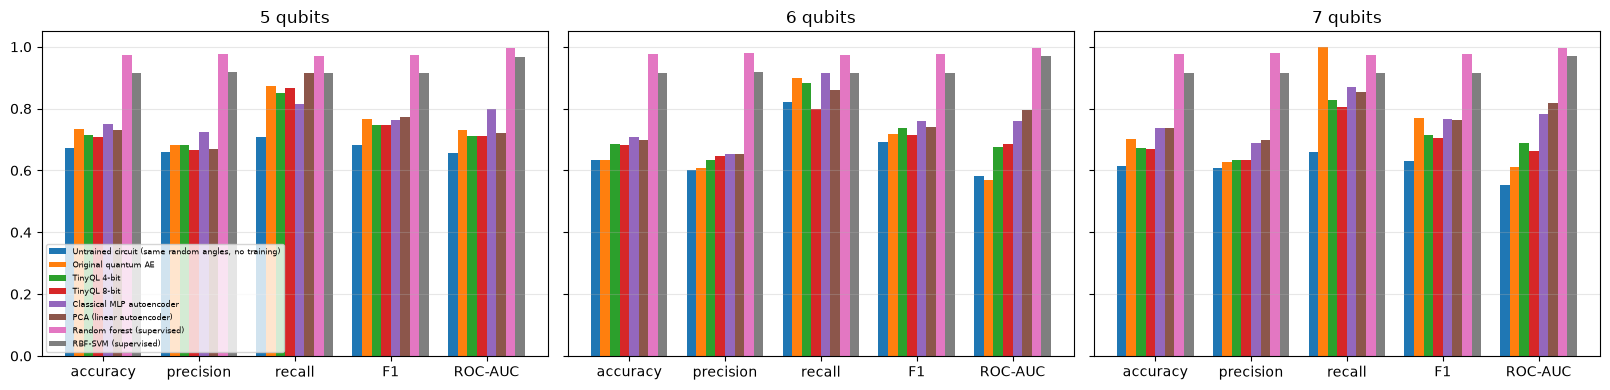

In [25]:
# Confusion matrices (attack = positive class) and the comparison bars of Figures 10-11
fig, axes = plt.subplots(1, len(QUBITS), figsize=(4.6 * len(QUBITS), 3.8))
for ax, n in zip(np.atleast_1d(axes), QUBITS):
    t = RES[(SEED, n)]["tiny"][8]
    ConfusionMatrixDisplay(confusion_matrix(t["y_te"], (t["s_te"] > t["thr"]).astype(int), labels=[0, 1]), display_labels=["benign", "attack"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"TinyQL 8-bit, {n} qubits\naccuracy {t['accuracy']:.3f}, recall {t['recall']:.3f}", fontsize=9)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(QUBITS), figsize=(5.4 * len(QUBITS), 4), sharey=True)
for ax, n in zip(np.atleast_1d(axes), QUBITS):
    sub = agg.loc[n].loc[order]
    xs = np.arange(len(MET)); wd = 0.8 / len(order)
    for i, (name, row) in enumerate(sub.iterrows()):
        ax.bar(xs + i * wd, [row[m] for m in MET], wd, label=name.replace(" (64-bit angles)", ""))
    ax.set_xticks(xs + 0.4 - wd / 2); ax.set_xticklabels(["accuracy", "precision", "recall", "F1", "ROC-AUC"]); ax.set_title(f"{n} qubits"); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3)
np.atleast_1d(axes)[0].legend(fontsize=6, loc="lower left")
plt.tight_layout(); plt.show()

## 8. Paper versus this notebook

Each row is one quantitative or qualitative claim of the paper. The verdict is **reproduced** when the notebook's value is within 2 accuracy points (0.02) of the paper's, **exceeded** / **not reached** when it is more than 2 points above / below, and **cannot be checked** when the paper gives no number that can be compared on this hardware or data. Values are means over the seeds of the run. The paper's Figures 10 and 11 (precision, recall, F1, ROC-AUC against the literature) print no numbers in the text, so only the notebook's own values are shown for them.

In [26]:
TOL = 0.02
def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "cannot be checked"
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached")

def mean_over_seeds(fn):
    return float(np.mean([fn(s) for s in SEEDS]))

claims = []
for n in QUBITS:
    ours = mean_over_seeds(lambda s: RES[(s, n)]["tiny"][8]["accuracy"])
    claims.append(("Table I", f"{n}-qubit TinyQL (8-bit) accuracy", PAPER_T1[n][0], ours, verdict(PAPER_T1[n][0], ours)))
best = max(((n, b, mean_over_seeds(lambda s: RES[(s, n)]["tiny"][b]["accuracy"])) for n in QUBITS for b in BITS), key=lambda z: z[2])
claims.append(("Abstract", f"best optimised model accuracy (here: {best[0]} qubits, {best[1]}-bit)", 0.9808, best[2], verdict(0.9808, best[2])))
fid_best = max(mean_over_seeds(lambda s: RES[(s, n)]["tiny"][8]["fid_benign"]) for n in QUBITS)
claims.append(("Table I (alt. reading)", "accuracy read as mean reconstruction fidelity of benign flows (best qubit count)", 0.9806, fid_best, verdict(0.9806, fid_best)))
tt = [mean_over_seeds(lambda s: RES[(s, n)]["base"]["train_s"]) for n in QUBITS]
claims.append(("Table I", "training time grows with qubit count (87.6 s < 314.6 s < 425.8 s)", "increasing", " < ".join(f"{t:.0f} s" for t in tt),
               "reproduced" if all(a < b for a, b in zip(tt, tt[1:])) else "not reached"))
claims.append(("Table I", "absolute training times (their data size and hardware)", "87.6 / 314.6 / 425.8 s", " / ".join(f"{t:.0f}" for t in tt) + " s", "cannot be checked"))
ms = mean_over_seeds(lambda s: np.mean([RES[(s, n)]["tiny"][8]["mem_saving"] for n in QUBITS]))
claims.append(("Abstract", "memory saving of the optimised model vs the original (50 % pruning x 64-bit -> 8-bit)", 0.9375, ms, verdict(0.9375, ms)))
pf8 = mean_over_seeds(lambda s: np.mean([RES[(s, n)]["tiny"][8]["prune_frac"] for n in QUBITS]))
claims.append(("Sec. III-C / IV-E", "pruning removes about 50 % of the parameters (8-bit: 42-53 %)", "0.42 - 0.53", pf8, "reproduced" if 0.42 <= pf8 <= 0.53 else verdict(0.475, pf8)))
pf4 = mean_over_seeds(lambda s: np.mean([RES[(s, n)]["tiny"][4]["prune_frac"] for n in QUBITS]))
claims.append(("Sec. IV-E", "4-bit TinyQL shows no parameter reduction", 0.0, pf4, "reproduced" if pf4 <= TOL else "not reproduced (this run prunes the 4-bit models too)"))
acc_o = mean_over_seeds(lambda s: np.mean([RES[(s, n)]["base"]["accuracy"] for n in QUBITS]))
acc_t = mean_over_seeds(lambda s: np.mean([RES[(s, n)]["tiny"][8]["accuracy"] for n in QUBITS]))
claims.append(("Abstract", "compression without loss of accuracy: TinyQL 8-bit minus original (mean over qubit counts)", ">= -0.02", acc_t - acc_o, "reproduced" if acc_t - acc_o >= -TOL else "not reached"))
kept_t = mean_over_seeds(lambda s: np.mean([RES[(s, n)]["tiny"][8]["kept"] for n in QUBITS])); ae_p = mean_over_seeds(lambda s: np.mean([RES[(s, n)]["cls"]["Classical MLP autoencoder"]["params"] for n in QUBITS]))
claims.append(("Abstract", "TinyQL needs substantially fewer parameters than a classical autoencoder", "fewer", f"{kept_t:.0f} vs {ae_p:.0f}", "reproduced" if kept_t < ae_p else "not reached"))
acc_ae = mean_over_seeds(lambda s: np.mean([RES[(s, n)]["cls"]["Classical MLP autoencoder"]["accuracy"] for n in QUBITS]))
claims.append(("Abstract / RQ1", "detection accuracy not below the classical autoencoder's (TinyQL 8-bit minus MLP autoencoder)", ">= -0.02", acc_t - acc_ae, "reproduced" if acc_t - acc_ae >= -TOL else "not reached"))
acc_n = [mean_over_seeds(lambda s: RES[(s, n)]["tiny"][8]["accuracy"]) for n in QUBITS]
claims.append(("Sec. IV-B", "more qubits give equal or higher accuracy (5 <= 6 <= 7)", "non-decreasing", " <= ".join(f"{a:.3f}" for a in acc_n),
               "reproduced" if all(b >= a - 0.01 for a, b in zip(acc_n, acc_n[1:])) else "not reached"))
mt = [mean_over_seeds(lambda s: RES[(s, n)]["base"]["mem_train_mb"]) for n in QUBITS]
claims.append(("Sec. IV-C", "training memory grows with qubit count", "increasing", " < ".join(f"{m:.1f} MB" for m in mt), "reproduced" if all(a < b for a, b in zip(mt, mt[1:])) else "not reached"))
sota = {m: mean_over_seeds(lambda s: RES[(s, QUBITS[-1])]["tiny"][8][m]) for m in ("precision", "recall", "f1", "roc_auc")}
claims.append(("Figs. 10-11", f"precision / recall / F1 / ROC-AUC of the {QUBITS[-1]}-qubit TinyQL against the literature (values only in the figure)", "figure only",
               " / ".join(f"{v:.3f}" for v in sota.values()), "cannot be checked"))
CLAIMS = pd.DataFrame(claims, columns=["where", "claim", "paper", "notebook", "verdict"])
CLAIMS["notebook"] = [round(v, 4) if isinstance(v, float) else v for v in CLAIMS["notebook"]]
pd.set_option("display.max_colwidth", 110)
display(CLAIMS)
print(CLAIMS.verdict.value_counts().to_string())
print(f"\nNotebook wall-clock: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min")

,where,claim,paper,notebook,verdict
0,Table I,5-qubit TinyQL (8-bit) accuracy,0.877,0.7086,not reached
1,Table I,6-qubit TinyQL (8-bit) accuracy,0.978,0.6813,not reached
2,Table I,7-qubit TinyQL (8-bit) accuracy,0.9806,0.6695,not reached
3,Abstract,"best optimised model accuracy (here: 5 qubits, 4-bit)",0.9808,0.7156,not reached
4,Table I (alt. reading),accuracy read as mean reconstruction fidelity of benign flows (best qubit count),0.9806,0.2181,not reached
5,Table I,training time grows with qubit count (87.6 s < 314.6 s < 425.8 s),increasing,130 s < 171 s < 236 s,reproduced
6,Table I,absolute training times (their data size and hardware),87.6 / 314.6 / 425.8 s,130 / 171 / 236 s,cannot be checked
7,Abstract,memory saving of the optimised model vs the original (50 % pruning x 64-bit -> 8-bit),0.9375,0.921,reproduced
8,Sec. III-C / IV-E,pruning removes about 50 % of the parameters (8-bit: 42-53 %),0.42 - 0.53,0.3677,not reached
9,Sec. IV-E,4-bit TinyQL shows no parameter reduction,0.0,0.3161,not reproduced (this run prunes the 4-bit models too)


verdict
not reached                                              8
reproduced                                               5
cannot be checked                                        2
not reproduced (this run prunes the 4-bit models too)    1

Notebook wall-clock: 23.6 min


## Reading the paper critically

*(Numbers refer to the executed run stored in this notebook: `FAST_MODE = False`, two seeds, 1,600 + 1,600 flows; they will move by a few points with other seeds or sample sizes.)*

**The headline accuracies are not reached, and the paper does not say what "accuracy" is.** The paper reports 87.7 %, 97.8 % and 98.1 % for 5, 6 and 7 qubits. With the most natural reading, a threshold on the reconstruction infidelity applied to a balanced benign/attack test set, this notebook obtains about 71 %, 68 % and 67 % for the 8-bit TinyQL models. With the other plausible reading, the reconstruction fidelity itself, the original circuits reach 0.34-0.49 and the TinyQL circuits only 0.09-0.22, far from 0.98. The paper never defines the label rule, the sample, the split or the feature set, so the gap may come from a different task definition rather than from the method, but nothing in the text allows the numbers to be re-derived. A supervised random forest on the very same amplitude vectors reaches about 97 %, which shows that the information is in the data and that the weak point is the autoencoder detector.

**Training the circuit barely changes the detector.** An untrained circuit with the same random angles already reaches 61-67 % accuracy; the trained original models reach 64-73 %. The validation-accuracy curves peak within the first few epochs and then fall or stay flat while the fidelity keeps rising, i.e. the quantity the loss optimises is not the quantity that separates attacks from benign flows. A linear autoencoder (PCA) and an MLP autoencoder on the same inputs reach 70-74 %, a little above every quantum model. With 60-84 rotation angles and a hardware-efficient ansatz, the circuit cannot reconstruct 32-128 dimensional flow vectors well (the best mean fidelity is about 0.5), so what remains is mostly a random projection of the flow.

**Compression "without loss of accuracy" is true here only because there is little to lose.** TinyQL 8-bit is within 0.4 points of the original on average, but the original is weak and noisy (the standard deviation over just two seeds reaches 13 accuracy points for the 6-qubit original), and the guard of Algorithm 1 works on a validation split of 320 flows whose own sampling error (about 2.5 points) is half of the 5-point tolerance. Pruning removed 37 % of the parameters on average instead of about 50 %, the 4-bit models were pruned as well (the paper says they keep all parameters), and the fidelity of the compressed circuits dropped sharply, which the accuracy metric hides.

**The 93.75 % memory saving is arithmetic, not an experiment.** Removing half of the parameters and shrinking the rest from 64 to 8 bits leaves `0.5 * 8/64 = 6.25 %`, i.e. a saving of 93.75 % whatever the data; the paper's split "50 % from pruning and 43.75 % from bit precision" is not how the two factors combine. The notebook reproduces the figure only when exactly half of the angles are removed (92.1 % here). The payload is also tiny (30-48 bytes) compared with the per-layer scale and zero-point that a device must store as well (40 bytes in this implementation), so the saving including that overhead is closer to 85 %. Table I's "classical memory" `2 * 2^n` bytes is a formula, not a measurement; a complex128 statevector of the simulated circuit needs `16 * 2^(n + trash)` bytes.

**Quantum simulation on an edge device is not obviously a win.** A classical simulator needs memory and time that grow as `2^n`, which the measured peak memory (about 4, 10 and 31 MB for 5, 6 and 7 qubits) and the training times show; the classical MLP autoencoder for the same input trains in a couple of seconds. The comparison with a 1,352 to 20,768 parameter MLP flatters TinyQL because a 60-84 parameter model is compared with a model hundreds of times larger; PCA with the same latent size is a far simpler baseline that the paper does not include. Exercise 4 asks for the fair version.

**Open points of the method.** The entropy criterion is under-specified (which density matrix, how it is averaged, whether pruning low entropy is meaningful when low entropy can also mean a well-trained, nearly pure qubit); the threshold iteration `0.9 * tau_S` can need many rounds because the entropies are clustered; the fine-tuning budget (10 % of the epochs) is small compared with the damage done by deleting half of the rotations; and the paper gives no seeds, no confidence intervals and no code details beyond a repository link, so claims about "up to 98.08 %" cannot be separated from a favourable run.

## Exercises

1. **Depth and size of the latent register.** Change `N_LAYERS` (try 1, 3, 5) and `N_TRASH` (1, 2, 3). How do the reconstruction fidelity, the detection accuracy and the number of parameters that survive pruning move?
2. **A different entropy.** The notebook uses the entropy of the single qubit a gate acts on. Replace it by the entanglement entropy between the first `k` qubits and the rest, or by the variance of the loss under a shift of the parameter. Which parameters does each criterion remove, and does the accuracy guard of Algorithm 1 still pass?
3. **Quantisation before or after fine-tuning.** Move the quantisation of Phase 3 before the fine-tuning (quantisation-aware training with a straight-through estimator) and compare the 4-bit results with the post-training quantisation used here.
4. **A fairer classical autoencoder.** Shrink the MLP autoencoder until it has about as many parameters as the pruned quantum circuit (a few dozen) and compare accuracy again. What does this say about the paper's claim that TinyQL "requires substantially fewer parameters" for the same accuracy?
5. **Unseen attacks.** Train the autoencoder on benign flows only (as here) but report recall per attack family (DoS, DDoS, PortScan, brute force, botnet, web attacks) on the test split. Which families does reconstruction-fidelity detection miss, and why might a supervised random forest not have this problem?